# Distilling a black-box classifier into interpretable students

##### Mohamedalfateh Tagalsir Maroof Saeed

Part B of the assignment, in execution order:

1. Data acquisition and validation (two UCI datasets)
2. Stratified train / validation / test split
3. Exploratory data analysis on the training partition
4. Teacher: gradient-boosted trees, selected on validation data and then frozen
5. Students: a sparse PCE-HDMR polynomial and an additive spline model (GAM), both fitted to the teacher's scores
6. Test evaluation: accuracy, fidelity, complexity and failure analysis
7. Explanations: the students' built-in attributions and Sobol' indices compared with a post-hoc Shapley explainer of the teacher

## 1. Setup

In [1]:
import hashlib, io, itertools, os, re, time, urllib.request, warnings, zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.special import softmax
from scipy.stats import ks_2samp, kurtosis, skew, spearmanr
from sklearn.datasets import load_svmlight_file
from sklearn.decomposition import PCA
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.linear_model import OrthogonalMatchingPursuit, Ridge
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, confusion_matrix,
                             f1_score, log_loss, roc_auc_score)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import SplineTransformer, StandardScaler
from threadpoolctl import threadpool_limits

SEED = 42
ROOT = Path.cwd()
RAW = ROOT / 'data' / 'raw'
TABLES = ROOT / 'results' / 'tables'
FIGURES = ROOT / 'results' / 'figures'
for folder in (RAW, TABLES, FIGURES):
    folder.mkdir(parents=True, exist_ok=True)

threadpool_limits(limits=min(4, os.cpu_count() or 1))    # cap numerical threads
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
pd.set_option('display.float_format', '{:.4f}'.format)
pd.set_option('display.max_columns', 30)

COLORS = {'teacher': '#326e9b', 'PCE': '#378468', 'GAM': '#c07b31'}


def save_table(frame, name):
    """Write a table to results/tables and return it for display."""
    frame.to_csv(TABLES / f'{name}.csv', index=False)
    return frame


def save_figure(fig, name):
    fig.savefig(FIGURES / f'{name}.png', dpi=170, bbox_inches='tight')

## 2. Data acquisition and validation

Both datasets come from the UCI Machine Learning Repository. Each archive is downloaded once,
cached in `data/raw/` and checked against a fixed SHA-256 digest, so every run uses identical bytes (for reproducibility).

| Dataset | Role in the assignment | Source |
|---|---|---|
| HTRU2 (pulsar candidates) | 8-30 features | Lyon et al., UCI 372, doi:10.24432/C5DK6R |
| Gas Sensor Array Drift | at least 100 features | Vergara et al., UCI 224, doi:10.24432/C5RP6W |

In [2]:
SOURCES = {
    'htru2': {
        'name': 'HTRU2',
        'url': 'https://archive.ics.uci.edu/static/public/372/htru2.zip',
        'archive': 'htru2.zip',
        'sha256': 'ba442c076dd22a8952700f26e38499fc1806037dcf7bea0e125e6bfba393f379',
    },
    'gas': {
        'name': 'Gas Sensor Array Drift',
        'url': 'https://archive.ics.uci.edu/static/public/224/gas+sensor+array+drift+dataset.zip',
        'archive': 'gas_sensor_drift.zip',
        'sha256': '91e8f466f202e7a093d657673ce47311c3e90416f7df3057966058961c351fe4',
    },
}


def fetch_archive(key):
    """Return the cached archive, downloading it if needed and verifying its checksum."""
    source = SOURCES[key]
    path = RAW / source['archive']
    if not path.exists():
        request = urllib.request.Request(source['url'], headers={'User-Agent': 'Mozilla/5.0'})
        with urllib.request.urlopen(request, timeout=60) as response:
            path.write_bytes(response.read())
    if hashlib.sha256(path.read_bytes()).hexdigest() != source['sha256']:
        raise ValueError(f'{key}: archive checksum does not match the expected value')
    return path


def load_htru2():
    """HTRU2: eight statistics of the pulse profile and DM-SNR curve; binary target."""
    with zipfile.ZipFile(fetch_archive('htru2')) as archive:
        csv_name = next(n for n in archive.namelist() if n.endswith('HTRU_2.csv'))
        arff_name = next(n for n in archive.namelist() if n.endswith('HTRU_2.arff'))
        # The CSV has no header; column names are taken from the ARFF file.
        columns = [line.split()[1].strip('\'"') for line in archive.read(arff_name).decode().splitlines()
                   if line.lower().startswith('@attribute')]
        frame = pd.read_csv(io.BytesIO(archive.read(csv_name)), header=None, names=columns)
    labels = ['Profile mean', 'Profile SD', 'Profile skew', 'Profile kurt',
              'DM mean', 'DM SD', 'DM skew', 'DM kurt']
    return {'X': frame.iloc[:, :-1].to_numpy(dtype='float64'),
            'y': frame['class'].to_numpy(dtype='int64'),
            'features': columns[:-1], 'labels': labels,
            'class_names': {0: 'non_pulsar', 1: 'pulsar'}}


GAS_DESCRIPTORS = ['dR', 'norm-dR', 'rise-0.001', 'rise-0.01', 'rise-0.1',
                   'decay-0.001', 'decay-0.01', 'decay-0.1']


def load_gas():
    """Gas Sensor Array Drift: 16 sensors x 8 descriptors = 128 features; six gases; ten batches."""
    blocks, targets, batches = [], [], []
    with zipfile.ZipFile(fetch_archive('gas')) as archive:
        names = sorted((n for n in archive.namelist() if re.search(r'batch\d+\.dat$', n)),
                       key=lambda n: int(re.search(r'batch(\d+)', n).group(1)))
        for name in names:
            X, y = load_svmlight_file(io.BytesIO(archive.read(name)), n_features=128, zero_based=False)
            blocks.append(X.toarray())
            targets.append(y.astype('int64'))
            batches.append(np.full(len(y), int(re.search(r'batch(\d+)', name).group(1))))
    labels = [f'S{sensor:02d} {descriptor}' for sensor in range(1, 17) for descriptor in GAS_DESCRIPTORS]
    return {'X': np.vstack(blocks), 'y': np.concatenate(targets), 'batch': np.concatenate(batches),
            'features': [label.replace(' ', '_') for label in labels], 'labels': labels,
            'class_names': {1: 'ethanol', 2: 'ethylene', 3: 'ammonia',
                            4: 'acetaldehyde', 5: 'acetone', 6: 'toluene'}}


DATA = {'htru2': load_htru2(), 'gas': load_gas()}
for key, d in DATA.items():
    d['name'] = SOURCES[key]['name']
    d['classes'] = np.array(sorted(d['class_names']))
    print(f"{d['name']}: X {d['X'].shape}, classes {len(d['classes'])}")

HTRU2: X (17898, 8), classes 2
Gas Sensor Array Drift: X (13910, 128), classes 6


### Integrity checks and assignment constraints

The checks below confirm that the inputs are complete and finite, that no input row is duplicated
(duplicates could leak between partitions) and that each dataset meets the size constraints of task B1.

In [3]:
rows = []
for key, d in DATA.items():
    X, y = d['X'], d['y']
    counts = pd.Series(y).value_counts()
    rows.append({
        'dataset': d['name'], 'samples': len(X), 'features': X.shape[1], 'classes': len(counts),
        'missing_values': int(np.isnan(X).sum()), 'non_finite_values': int((~np.isfinite(X)).sum()),
        'duplicate_rows': int(pd.DataFrame(X).duplicated().sum()),
        'constant_features': int((X.std(axis=0) == 0).sum()),
        'minority_class_share': counts.min() / len(y),
    })
overview = save_table(pd.DataFrame(rows), 'dataset_overview')
display(overview)

assert (overview[['missing_values', 'non_finite_values', 'duplicate_rows']] == 0).all().all()
assert (overview['samples'] >= 2000).all()                                  # B1: at least 2,000 samples
assert 8 <= DATA['htru2']['X'].shape[1] <= 30                               # B1: moderate dimension
assert DATA['gas']['X'].shape[1] >= 100                                     # B1: high dimension

,dataset,samples,features,classes,missing_values,non_finite_values,duplicate_rows,constant_features,minority_class_share
0,HTRU2,17898,8,2,0,0,0,0,0.0916
1,Gas Sensor Array Drift,13910,128,6,0,0,0,0,0.1180


## 3. Train / validation / test split

A single class-stratified 60/20/20 split per dataset is used by every model.
Training data fit the models, validation data select their settings, and the test data are used once,
in Section 7. All exploratory analysis in Section 4 uses the training partition only.

In [4]:
def stratified_split(y, seed=SEED):
    """Return row indices for a class-stratified 60/20/20 split."""
    rows = np.arange(len(y))
    train, rest = train_test_split(rows, test_size=0.40, stratify=y, random_state=seed)
    validation, test = train_test_split(rest, test_size=0.50, stratify=y[rest], random_state=seed)
    return {'train': np.sort(train), 'validation': np.sort(validation), 'test': np.sort(test)}


rows = []
for key, d in DATA.items():
    d['idx'] = stratified_split(d['y'])
    for part, idx in d['idx'].items():
        d[f'X_{part}'], d[f'y_{part}'] = d['X'][idx], d['y'][idx]
        shares = pd.Series(d['y'][idx]).value_counts(normalize=True).sort_index()
        rows.append({'dataset': d['name'], 'partition': part, 'samples': len(idx),
                     **{d['class_names'][c]: share for c, share in shares.items()}})
split_summary = save_table(pd.DataFrame(rows), 'split_summary')
display(split_summary.fillna(''))

,dataset,partition,samples,non_pulsar,pulsar,ethanol,ethylene,ammonia,acetaldehyde,acetone,toluene
0,HTRU2,train,10738,0.9085,0.0915,,,,,,
1,HTRU2,validation,3580,0.9084,0.0916,,,,,,
2,HTRU2,test,3580,0.9084,0.0916,,,,,,
3,Gas Sensor Array Drift,train,8346,,,0.1844,0.2104,0.1180,0.1391,0.2163,0.1318
4,Gas Sensor Array Drift,validation,2782,,,0.1844,0.2103,0.1179,0.1391,0.2164,0.1319
5,Gas Sensor Array Drift,test,2782,,,0.1844,0.2103,0.1179,0.1395,0.2164,0.1316


## 4. Exploratory data analysis

Every statistic in this section is computed on the **training partition only**, so nothing learned here
can leak information from the validation or test data. The analysis answers five questions that shape
the modelling choices: how balanced the classes are, how the features are distributed and scaled,
which features separate the classes, how strongly the features depend on each other, and whether the
data are stationary.

### 4.1 Class balance

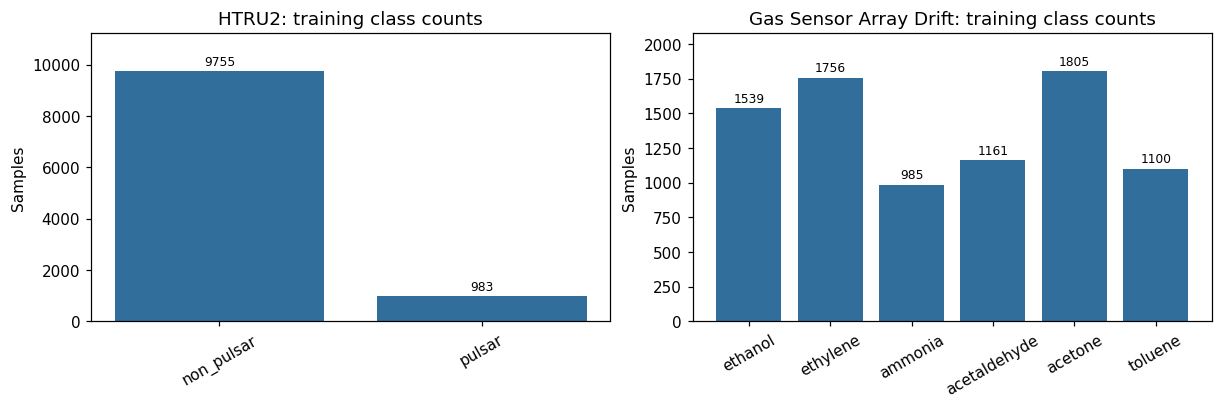

,dataset,largest_class,smallest_class,imbalance_ratio
0,HTRU2,9755,983,9.9237
1,Gas Sensor Array Drift,1805,985,1.8325


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), layout='constrained')
rows = []
for ax, (key, d) in zip(axes, DATA.items()):
    counts = pd.Series(d['y_train']).value_counts().sort_index()
    bars = ax.bar([d['class_names'][c] for c in counts.index], counts.values, color=COLORS['teacher'])
    ax.bar_label(bars, padding=2, fontsize=8)
    ax.set_title(f"{d['name']}: training class counts")
    ax.set_ylabel('Samples')
    ax.tick_params(axis='x', labelrotation=30)
    ax.margins(y=0.15)
    rows.append({'dataset': d['name'], 'largest_class': counts.max(), 'smallest_class': counts.min(),
                 'imbalance_ratio': counts.max() / counts.min()})
save_figure(fig, 'fig01_class_balance')
plt.show()
display(save_table(pd.DataFrame(rows), 'eda_class_balance'))

HTRU2 is strongly imbalanced, so plain accuracy would hide errors on the pulsar class. The teacher is
therefore selected by macro-F1 and trained with balanced class weights, and every later result is also
reported per class. The gas classes are only mildly imbalanced.

### 4.2 Feature scales, shapes and outliers

For each feature: location, spread, skewness, excess kurtosis and the share of values outside the
Tukey fences (1.5 x IQR beyond the quartiles).

In [6]:
def feature_summary(X, labels):
    """Location, spread, shape and outlier share of every feature."""
    q1, median, q3 = np.percentile(X, [25, 50, 75], axis=0)
    iqr = q3 - q1
    outside = (X < q1 - 1.5 * iqr) | (X > q3 + 1.5 * iqr)
    return pd.DataFrame({'feature': labels, 'mean': X.mean(axis=0), 'std': X.std(axis=0),
                         'min': X.min(axis=0), 'median': median, 'max': X.max(axis=0),
                         'skewness': skew(X, axis=0), 'excess_kurtosis': kurtosis(X, axis=0),
                         'outlier_share': outside.mean(axis=0)})


SUMMARY = {key: feature_summary(d['X_train'], d['labels']) for key, d in DATA.items()}
for key, summary in SUMMARY.items():
    save_table(summary, f'eda_feature_summary_{key}')

display(SUMMARY['htru2'])

# The 128 gas features are summarised by descriptor type (16 sensors each).
gas_summary = SUMMARY['gas'].assign(descriptor=[label.split(' ')[1] for label in DATA['gas']['labels']])
by_descriptor = gas_summary.groupby('descriptor', sort=False).agg(
    median_std=('std', 'median'), min_std=('std', 'min'), max_std=('std', 'max'),
    median_abs_skewness=('skewness', lambda s: s.abs().median()),
    median_outlier_share=('outlier_share', 'median')).reset_index()
display(save_table(by_descriptor, 'eda_gas_summary_by_descriptor'))

scale_rows = [{'dataset': DATA[key]['name'],
               'largest_to_smallest_std_ratio': s['std'].max() / s['std'].min(),
               'features_with_abs_skewness_above_2': int((s['skewness'].abs() > 2).sum()),
               'median_outlier_share': s['outlier_share'].median()} for key, s in SUMMARY.items()]
display(save_table(pd.DataFrame(scale_rows), 'eda_scale_and_shape'))

,feature,mean,std,min,median,max,skewness,excess_kurtosis,outlier_share
0,Profile mean,111.0197,25.4460,5.8125,115.0117,192.6172,-1.3878,3.0007,0.0572
1,Profile SD,46.5198,6.7831,24.7720,46.9556,91.2065,0.0299,1.2267,0.0142
2,Profile skew,0.4771,1.0595,-1.8760,0.2247,8.0695,3.6777,14.9584,0.0887
3,Profile kurt,1.7618,6.1620,-1.7919,0.1923,68.1016,5.2393,31.0230,0.1104
4,DM mean,12.3838,28.7639,0.2132,2.8161,222.4214,3.6994,14.2620,0.1609
5,DM SD,26.3040,19.3587,7.3704,18.5454,110.6422,1.9007,2.8738,0.1293
6,DM skew,8.2879,4.4887,-3.1393,8.3940,34.5398,0.4566,1.5319,0.0258
7,DM kurt,104.3402,106.1462,-1.9770,82.0568,1191.0008,2.7320,13.4483,0.0493


,descriptor,median_std,min_std,max_std,median_abs_skewness,median_outlier_share
0,dR,13375.2617,2108.3340,68909.7076,1.2662,0.0193
1,norm-dR,4.6928,1.6108,341.0881,3.4523,0.0587
2,rise-0.001,4.7930,0.7093,17.4029,1.2809,0.0338
3,rise-0.01,12.2953,2.1017,24.5736,2.0382,0.0338
4,rise-0.1,15.5593,5.4427,137.4772,3.9759,0.0338
5,decay-0.001,3.6244,0.5290,12.5544,1.6647,0.0283
6,decay-0.01,6.3676,0.9243,21.1837,2.9440,0.0326
7,decay-0.1,18.4229,4.8244,157.8541,7.0027,0.0393


,dataset,largest_to_smallest_std_ratio,features_with_abs_skewness_above_2,median_outlier_share
0,HTRU2,100.1875,4,0.0729
1,Gas Sensor Array Drift,130263.3839,77,0.0356


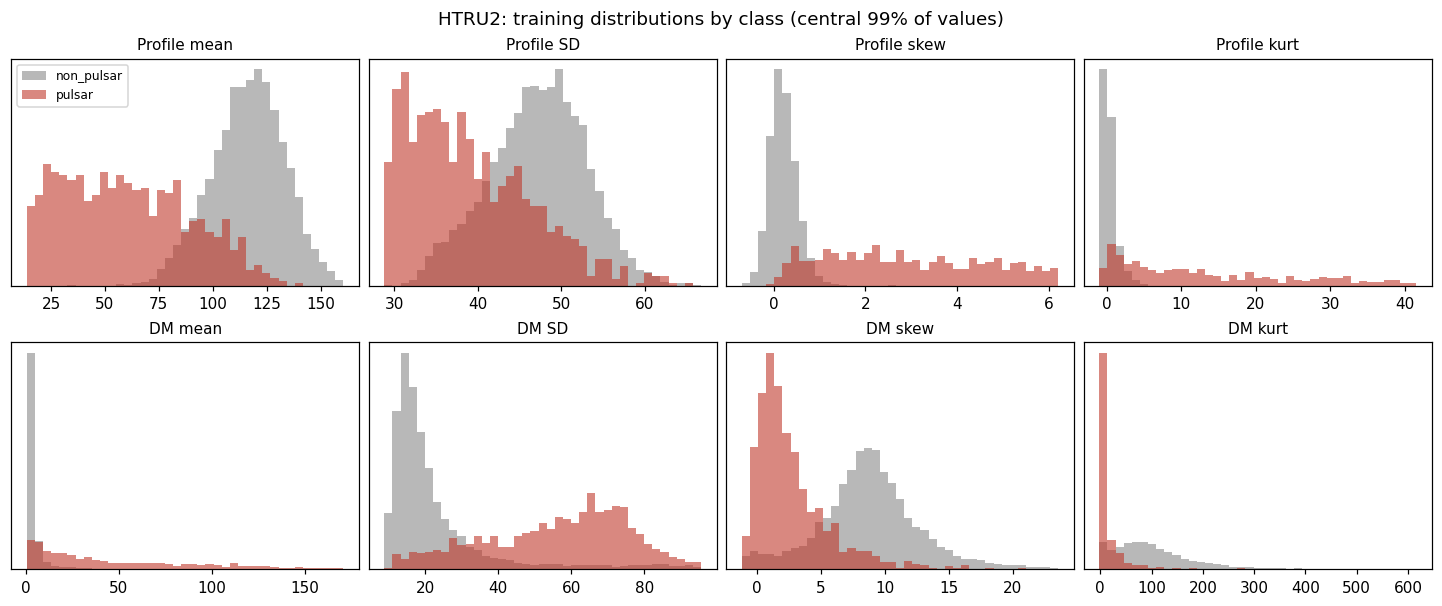

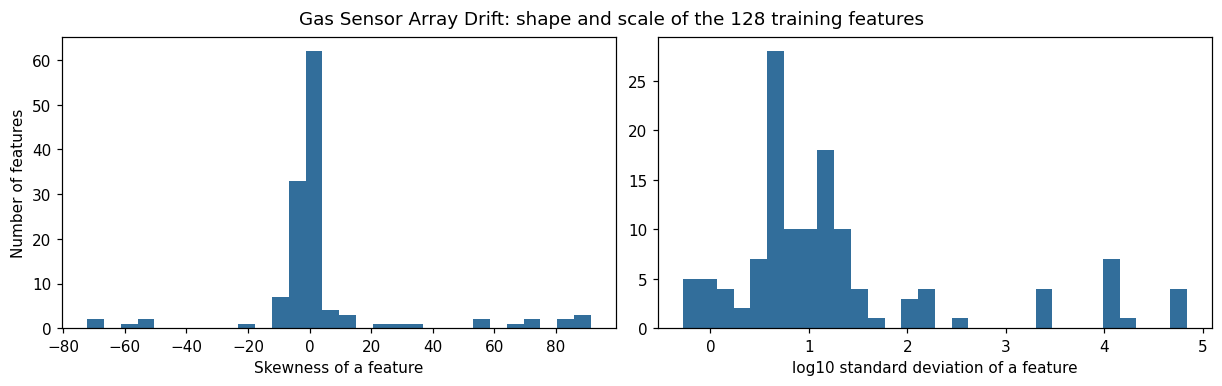

In [7]:
# HTRU2: class-conditional distribution of each feature.
d = DATA['htru2']
fig, axes = plt.subplots(2, 4, figsize=(13, 5.4), layout='constrained')
for j, ax in enumerate(axes.ravel()):
    low, high = np.percentile(d['X_train'][:, j], [0.5, 99.5])
    bins = np.linspace(low, high, 40)
    for c, color in zip(d['classes'], ['#8a8a8a', '#c0392b']):
        ax.hist(d['X_train'][d['y_train'] == c, j], bins=bins, density=True, alpha=0.6,
                color=color, label=d['class_names'][c])
    ax.set_title(d['labels'][j], fontsize=10)
    ax.set_yticks([])
axes[0, 0].legend(fontsize=8)
fig.suptitle('HTRU2: training distributions by class (central 99% of values)')
save_figure(fig, 'fig02_htru2_distributions')
plt.show()

# Gas: distribution of skewness and scale across the 128 features.
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), layout='constrained')
axes[0].hist(SUMMARY['gas']['skewness'], bins=30, color=COLORS['teacher'])
axes[0].set_xlabel('Skewness of a feature')
axes[0].set_ylabel('Number of features')
axes[1].hist(np.log10(SUMMARY['gas']['std']), bins=30, color=COLORS['teacher'])
axes[1].set_xlabel('log10 standard deviation of a feature')
fig.suptitle('Gas Sensor Array Drift: shape and scale of the 128 training features')
save_figure(fig, 'fig03_gas_shape_and_scale')
plt.show()

The features are far from Gaussian and differ in scale by orders of magnitude. Two consequences follow.
First, the polynomial student needs a basis that is standardised and orthogonalised against the
*empirical* distribution of each feature rather than a Gaussian or uniform assumption (Section 6.2).
Second, heavy tails mean that some test points lie far from the bulk of the training data, where a
polynomial extrapolates poorly; the spline student is given linear extrapolation for the same reason.

### 4.3 Which features separate the classes?

Univariate relevance is measured by mutual information between each feature and the class label
(non-parametric, so it also captures non-monotone effects). For the binary HTRU2 task the ROC AUC of
each single feature is reported as well.

,feature,mutual_information,single_feature_auc
2,Profile skew,0.2253,0.9708
3,Profile kurt,0.1900,0.9381
0,Profile mean,0.1884,0.9475
5,DM SD,0.1167,0.8963
4,DM mean,0.1153,0.8943
7,DM kurt,0.1138,0.8876
6,DM skew,0.1129,0.8854
1,Profile SD,0.0847,0.8122


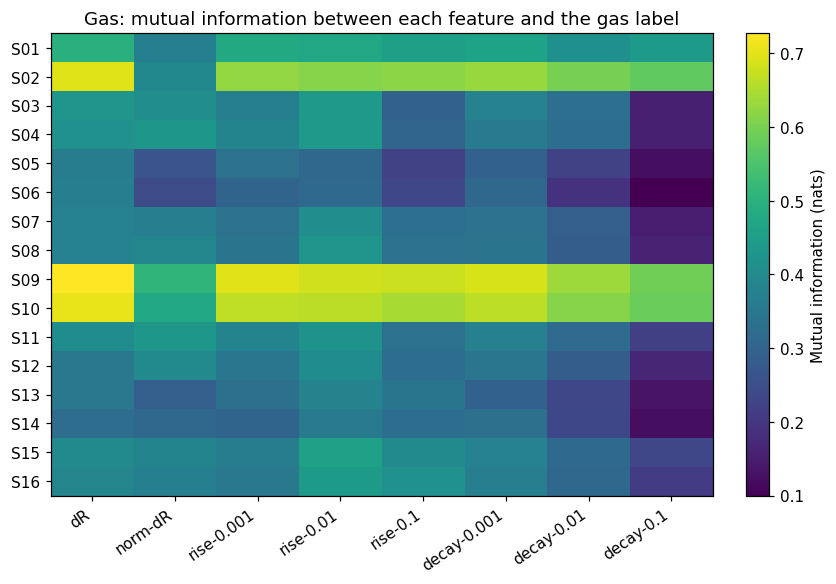

Gas features with mutual information above half of the maximum: 68 of 128


In [8]:
RELEVANCE = {}
for key, d in DATA.items():
    Xs = StandardScaler().fit_transform(d['X_train'])
    RELEVANCE[key] = mutual_info_classif(Xs, d['y_train'], random_state=SEED)

d = DATA['htru2']
auc = np.array([roc_auc_score(d['y_train'], d['X_train'][:, j]) for j in range(d['X'].shape[1])])
htru_relevance = pd.DataFrame({'feature': d['labels'], 'mutual_information': RELEVANCE['htru2'],
                               'single_feature_auc': np.maximum(auc, 1 - auc)})
display(save_table(htru_relevance.sort_values('mutual_information', ascending=False), 'eda_htru2_relevance'))

d = DATA['gas']
gas_relevance = pd.DataFrame({'feature': d['labels'], 'mutual_information': RELEVANCE['gas']})
save_table(gas_relevance.sort_values('mutual_information', ascending=False), 'eda_gas_relevance')
grid = RELEVANCE['gas'].reshape(16, 8)                     # rows: sensors, columns: descriptors

fig, ax = plt.subplots(figsize=(7.5, 5.2), layout='constrained')
image = ax.imshow(grid, cmap='viridis', aspect='auto')
ax.set_xticks(range(8), GAS_DESCRIPTORS, rotation=35, ha='right')
ax.set_yticks(range(16), [f'S{s:02d}' for s in range(1, 17)])
ax.set_title('Gas: mutual information between each feature and the gas label')
fig.colorbar(image, ax=ax, label='Mutual information (nats)')
save_figure(fig, 'fig04_gas_relevance')
plt.show()
print('Gas features with mutual information above half of the maximum:',
      int((RELEVANCE['gas'] > 0.5 * RELEVANCE['gas'].max()).sum()), 'of 128')

Every HTRU2 feature is informative on its own (single-feature AUC of at least 0.81); the three
statistics of the pulse profile are the strongest. In the gas data the information is not concentrated
in a handful of features: more than half of the 128 features reach at least half of the highest mutual
information, across most sensors and descriptor types. A faithful student is therefore likely to need
many features, and a sparse student has to choose among near-equivalent ones.

### 4.4 Dependence between features

Sobol' indices and the orthogonality of a tensor-product polynomial basis assume independent inputs.
This section measures how far the data are from that assumption, using Spearman rank correlation
(robust to the skewed marginals seen above) and the number of principal components needed to
reproduce the variance of the standardised features.

,dataset,feature_pairs,median_abs_spearman,share_of_pairs_above_0.8,share_of_pairs_above_0.95,components_for_95pct_variance,components_for_99pct_variance
0,HTRU2,28,0.1019,0.2857,0.1786,5,6
1,Gas Sensor Array Drift,8128,0.6755,0.3241,0.0583,12,24


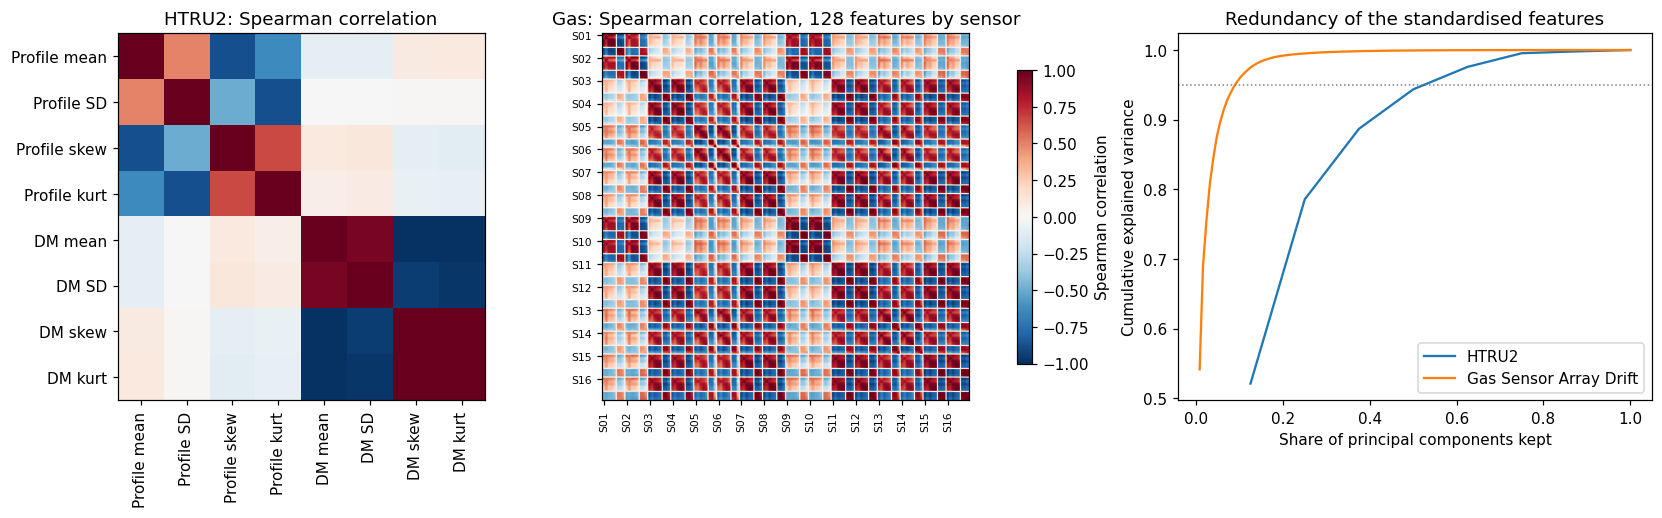

In [9]:
CORR = {key: pd.DataFrame(d['X_train']).corr(method='spearman').to_numpy() for key, d in DATA.items()}

rows = []
for key, d in DATA.items():
    off_diagonal = np.abs(CORR[key][np.triu_indices_from(CORR[key], k=1)])
    cumulative = np.cumsum(PCA().fit(StandardScaler().fit_transform(d['X_train'])).explained_variance_ratio_)
    d['pca_cumulative'] = cumulative
    rows.append({'dataset': d['name'], 'feature_pairs': len(off_diagonal),
                 'median_abs_spearman': np.median(off_diagonal),
                 'share_of_pairs_above_0.8': (off_diagonal > 0.8).mean(),
                 'share_of_pairs_above_0.95': (off_diagonal > 0.95).mean(),
                 'components_for_95pct_variance': int(np.searchsorted(cumulative, 0.95) + 1),
                 'components_for_99pct_variance': int(np.searchsorted(cumulative, 0.99) + 1)})
display(save_table(pd.DataFrame(rows), 'eda_dependence'))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), layout='constrained')
image = axes[0].imshow(CORR['htru2'], vmin=-1, vmax=1, cmap='RdBu_r')
axes[0].set_xticks(range(8), DATA['htru2']['labels'], rotation=90)
axes[0].set_yticks(range(8), DATA['htru2']['labels'])
axes[0].set_title('HTRU2: Spearman correlation')
axes[1].imshow(CORR['gas'], vmin=-1, vmax=1, cmap='RdBu_r')
ticks = np.arange(0, 128, 8)
axes[1].set_xticks(ticks, [f'S{s:02d}' for s in range(1, 17)], rotation=90, fontsize=7)
axes[1].set_yticks(ticks, [f'S{s:02d}' for s in range(1, 17)], fontsize=7)
axes[1].set_title('Gas: Spearman correlation, 128 features by sensor')
fig.colorbar(image, ax=axes[:2], shrink=0.8, label='Spearman correlation')
for key, d in DATA.items():
    share = np.arange(1, len(d['pca_cumulative']) + 1) / len(d['pca_cumulative'])
    axes[2].plot(share, d['pca_cumulative'], label=d['name'])
axes[2].axhline(0.95, color='grey', linestyle=':', linewidth=1)
axes[2].set_xlabel('Share of principal components kept')
axes[2].set_ylabel('Cumulative explained variance')
axes[2].set_title('Redundancy of the standardised features')
axes[2].legend()
save_figure(fig, 'fig05_dependence')
plt.show()

HTRU2 contains a few almost collinear pairs (for example the skewness and kurtosis of the same curve)
among otherwise weakly related features. In the gas data dependence is pervasive: the median absolute
rank correlation is about 0.7, the descriptors of one sensor and the same descriptor across sensors
move together, and 12 principal components reproduce 95% of the variance of the 128 features.

The independence assumption behind Sobol' indices is therefore violated in both datasets, strongly so
in the gas data. In this notebook every variance-based or Shapley explanation is computed against an
explicitly declared reference distribution (the product of the training marginals), and the results are
read as statements about the models under that reference, not about the physical measurements.

### 4.5 Stationarity of the gas data

The gas measurements were collected in ten batches over 36 months and the sensors drift. For each
later batch, the two-sample Kolmogorov-Smirnov (KS) statistic against batch 1 is computed per feature
**within each gas**, so that changes in the gas mixture between batches are not mistaken for drift.
The statistic is summarised by its median over the 128 features and then averaged over the gases
with at least 30 training rows in both batches.

gas,batch,acetaldehyde,acetone,ammonia,ethanol,ethylene,toluene
0,1,18,43,50,49,67,50
1,2,64,313,63,94,224,4
2,3,144,163,119,236,298,0
3,4,17,8,9,32,26,0
4,5,25,41,13,16,20,0
5,6,20,356,69,309,351,276
6,7,441,378,217,400,366,337
7,8,18,90,19,11,15,11
8,9,46,51,72,37,31,64
9,10,368,362,354,355,358,358


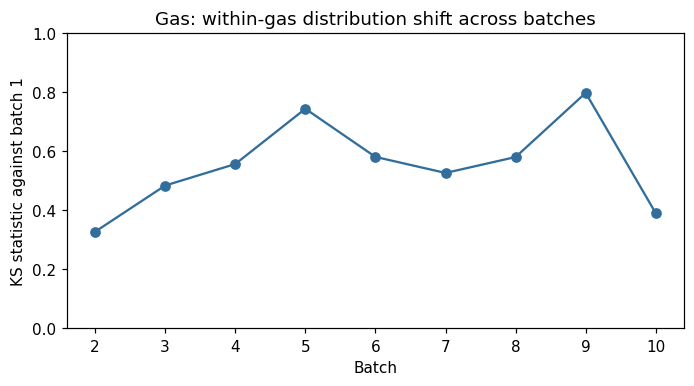

,batch,gases_compared,ks_vs_batch_1
0,2,4,0.3272
1,3,4,0.4838
2,4,1,0.5568
3,5,1,0.7442
4,6,5,0.5809
5,7,5,0.5265
6,8,1,0.5805
7,9,5,0.7981
8,10,5,0.3897


In [10]:
d = DATA['gas']
batch_train = d['batch'][d['idx']['train']]
display(save_table(pd.crosstab(batch_train, pd.Series(d['y_train']).map(d['class_names']).to_numpy(),
                               rownames=['batch'], colnames=['gas']).reset_index(), 'eda_gas_batch_counts'))

rows = []
for batch in range(2, 11):
    per_class = []
    for c in d['classes']:
        reference = d['X_train'][(batch_train == 1) & (d['y_train'] == c)]
        current = d['X_train'][(batch_train == batch) & (d['y_train'] == c)]
        if min(len(reference), len(current)) >= 30:
            per_class.append(np.median([ks_2samp(reference[:, j], current[:, j]).statistic
                                        for j in range(d['X'].shape[1])]))
    rows.append({'batch': batch, 'gases_compared': len(per_class),
                 'ks_vs_batch_1': float(np.mean(per_class)) if per_class else np.nan})
drift = save_table(pd.DataFrame(rows), 'eda_gas_drift')

fig, ax = plt.subplots(figsize=(6.2, 3.4), layout='constrained')
ax.plot(drift['batch'], drift['ks_vs_batch_1'], 'o-', color=COLORS['teacher'])
ax.set_xlabel('Batch')
ax.set_ylabel('KS statistic against batch 1')
ax.set_title('Gas: within-gas distribution shift across batches')
ax.set_ylim(0, 1)
save_figure(fig, 'fig06_gas_drift')
plt.show()
display(drift)

The feature distributions of the same gas change substantially between batches (a KS statistic of 0.3
to 0.8, where 0 means identical distributions and 1 means no overlap). Because the split is stratified
by class and pools all batches, the test results in this notebook measure performance on the pooled
distribution; they do not measure robustness to future drift.

### 4.6 Are the partitions comparable?

A per-feature KS test between the training and validation inputs checks that the random split did not
produce partitions with different distributions. With a correct split, about 1% of features should
fall below p = 0.01 by chance.

In [11]:
rows = []
for key, d in DATA.items():
    tests = [ks_2samp(d['X_train'][:, j], d['X_validation'][:, j]) for j in range(d['X'].shape[1])]
    rows.append({'dataset': d['name'], 'features': len(tests),
                 'max_ks_statistic': max(t.statistic for t in tests),
                 'features_with_p_below_0.01': sum(t.pvalue < 0.01 for t in tests)})
display(save_table(pd.DataFrame(rows), 'eda_split_comparability'))

,dataset,features,max_ks_statistic,features_with_p_below_0.01
0,HTRU2,8,0.0238,0
1,Gas Sensor Array Drift,128,0.0280,0


### 4.7 Implications for the experiment

| Finding | Consequence |
|---|---|
| HTRU2 is imbalanced | Balanced class weights for the teacher; macro-F1 for selection; per-class reporting |
| Skewed, heavy-tailed features on very different scales | Empirically standardised and orthogonalised polynomial basis; linear extrapolation for splines; out-of-range test points tracked in the failure analysis |
| Relevant information is spread over many gas features | Fidelity is reported against the number of features a student uses |
| Strong dependence between features | Explanations are computed against a declared product-of-marginals reference and interpreted with that caveat |
| Gas data drift across batches | Results describe the pooled distribution only |

## 5. Teacher: gradient-boosted trees

The black-box teacher is a histogram gradient-boosting classifier: an ensemble of a few hundred
regression trees per class, accurate on tabular data and not readable by inspection. Three
configurations fixed in advance are fitted on the training partition and the one with the highest
validation macro-F1 is kept (ties go to the smaller model). Trees are invariant to monotone
transformations, so the teacher uses the features on their original scale.

In [12]:
TEACHER_GRID = [
    {'candidate': 'hgb_120_15', 'max_iter': 120, 'max_leaf_nodes': 15, 'learning_rate': 0.08, 'l2_regularization': 1.0},
    {'candidate': 'hgb_180_15', 'max_iter': 180, 'max_leaf_nodes': 15, 'learning_rate': 0.08, 'l2_regularization': 1.0},
    {'candidate': 'hgb_180_31', 'max_iter': 180, 'max_leaf_nodes': 31, 'learning_rate': 0.08, 'l2_regularization': 3.0},
]


def score_probabilities(scores):
    """Class probabilities from log-odds scores measured against the reference (first) class."""
    return softmax(np.column_stack([np.zeros(len(scores)), scores]), axis=1)


def predictive_metrics(y, probabilities, classes):
    """Accuracy measures against the observed labels."""
    predicted = classes[np.argmax(probabilities, axis=1)]
    return {'accuracy': accuracy_score(y, predicted),
            'balanced_accuracy': balanced_accuracy_score(y, predicted),
            'macro_f1': f1_score(y, predicted, average='macro', zero_division=0),
            'log_loss': log_loss(y, probabilities, labels=classes)}


rows = []
for key, d in DATA.items():
    fitted = []
    for spec in TEACHER_GRID:
        params = {name: value for name, value in spec.items() if name != 'candidate'}
        model = HistGradientBoostingClassifier(**params, loss='log_loss', min_samples_leaf=30,
                                               early_stopping=False, class_weight='balanced',
                                               random_state=SEED).fit(d['X_train'], d['y_train'])
        train = predictive_metrics(d['y_train'], model.predict_proba(d['X_train']), d['classes'])
        validation = predictive_metrics(d['y_validation'], model.predict_proba(d['X_validation']), d['classes'])
        fitted.append((model, spec, validation['macro_f1']))
        rows.append({'dataset': d['name'], 'candidate': spec['candidate'],
                     'train_macro_f1': train['macro_f1'],
                     **{f'validation_{name}': value for name, value in validation.items()}})
    # Highest validation macro-F1; ties are broken in favour of fewer leaves, then fewer trees.
    model, spec, _ = min(fitted, key=lambda item: (-item[2], item[1]['max_leaf_nodes'], item[1]['max_iter']))
    d['teacher'], d['teacher_name'] = model, spec['candidate']

teacher_validation = pd.DataFrame(rows)
chosen = {d['name']: d['teacher_name'] for d in DATA.values()}
teacher_validation['selected'] = teacher_validation['candidate'] == teacher_validation['dataset'].map(chosen)
display(save_table(teacher_validation, 'teacher_validation'))

,dataset,candidate,train_macro_f1,validation_accuracy,validation_balanced_accuracy,validation_macro_f1,validation_log_loss,selected
0,HTRU2,hgb_120_15,0.9499,0.9690,0.9418,0.9129,0.1053,False
1,HTRU2,hgb_180_15,0.9658,0.9709,0.9401,0.9172,0.0978,False
2,HTRU2,hgb_180_31,0.9794,0.9746,0.9367,0.9256,0.0903,True
3,Gas Sensor Array Drift,hgb_120_15,1.0000,0.9935,0.9926,0.9932,0.0359,False
4,Gas Sensor Array Drift,hgb_180_15,1.0000,0.9939,0.9930,0.9936,0.0364,True
5,Gas Sensor Array Drift,hgb_180_31,1.0000,0.9932,0.9921,0.9928,0.0362,False


### The distillation target

From here on the teachers are frozen: they are only queried, never refitted. The students do not learn
the class labels; they learn the teacher's **log-odds scores**. For $K$ classes the target is the vector
of $K-1$ contrasts $s_k(x) = \log p_k(x) - \log p_{\mathrm{ref}}(x)$ against a fixed reference class
(non-pulsar; ethanol). Log-odds are unbounded, so a regression model can fit them without leaving the
valid range, and the class probabilities are recovered exactly by a softmax over $(0, s_1, \dots, s_{K-1})$.

In [13]:
def teacher_scores(teacher, X):
    """Teacher log-odds of each class against the reference class, shape (n, K-1)."""
    raw = np.asarray(teacher.decision_function(X), dtype='float64')
    return raw[:, None] if raw.ndim == 1 else raw[:, 1:] - raw[:, [0]]


rows = []
for key, d in DATA.items():
    reference = d['class_names'][d['classes'][0]]
    d['score_names'] = [f"{d['class_names'][c]} vs {reference}" for c in d['classes'][1:]]
    for part in ('train', 'validation'):
        d[f'T_{part}'] = teacher_scores(d['teacher'], d[f'X_{part}'])
        # The contrasts reproduce the teacher's probabilities exactly.
        assert np.allclose(score_probabilities(d[f'T_{part}']), d['teacher'].predict_proba(d[f'X_{part}']), atol=1e-10)
    # Normalising constant for score errors: root mean variance of the training scores.
    d['score_scale'] = float(np.sqrt(np.mean(np.var(d['T_train'], axis=0))))
    d['teacher_fingerprint'] = hashlib.sha256(d['T_train'].tobytes()).hexdigest()
    rows.append({'dataset': d['name'], 'teacher': d['teacher_name'], 'reference_class': reference,
                 'scores_to_distil': len(d['score_names']), 'training_score_scale': d['score_scale']})
display(pd.DataFrame(rows))

,dataset,teacher,reference_class,scores_to_distil,training_score_scale
0,HTRU2,hgb_180_31,non_pulsar,1,3.7414
1,Gas Sensor Array Drift,hgb_180_15,ethanol,5,6.8049


## 6. Students

Both students are regression models fitted to the same teacher scores on the same training rows.

| Student | Form | Why it is interpretable |
|---|---|---|
| Sparse PCE-HDMR | Degree-2 polynomial: main effects and a few pairwise products, terms chosen by orthogonal matching pursuit | A short closed-form formula; Sobol' indices follow directly from the coefficients |
| Additive spline model (GAM) | Sum of one smooth cubic-spline curve per feature | Every feature's effect can be plotted as a single curve; no interactions |

**Fidelity** is measured against the teacher, not against the labels:

* *score NRMSE*: root mean squared difference between student and teacher scores divided by the
  training score scale (0 is a perfect copy; 1 is no better than predicting the mean score);
* *teacher agreement*: share of cases where student and teacher predict the same class.

Each student is fitted at several complexity levels. The level with the lowest **validation** score
NRMSE is selected, with ties going to the simpler model.

In [14]:
PCE_BUDGETS = {'htru2': [4, 8, 16, 32], 'gas': [8, 16, 32, 64]}     # polynomial terms per score
PAIR_CANDIDATES = 128                                               # pairwise terms kept after screening
GAM_FEATURES = {'htru2': [2, 4, 8], 'gas': [8, 16, 32, 64, 128]}    # features given a spline
GAM_ALPHAS = [0.01, 1.0, 100.0]                                     # ridge penalties
GAM_KNOTS = 5
TOL = 1e-10                                                         # threshold for a non-zero coefficient


def fidelity_metrics(d, part, scores):
    """Fidelity to the teacher and accuracy against the labels on one partition."""
    target = d[f'T_{part}']
    error = scores - target
    probabilities = score_probabilities(scores)
    student_labels = d['classes'][probabilities.argmax(axis=1)]
    teacher_labels = d['classes'][score_probabilities(target).argmax(axis=1)]
    rmse = float(np.sqrt(np.mean(error ** 2)))
    return {'score_nrmse': rmse / d['score_scale'], 'score_rmse': rmse,
            'score_mae': float(np.mean(np.abs(error))),
            'score_median_abs_error': float(np.median(np.abs(error))),
            'teacher_agreement': float(np.mean(student_labels == teacher_labels)),
            **predictive_metrics(d[f'y_{part}'], probabilities, d['classes'])}

### 6.1 Sparse PCE-HDMR student

A polynomial chaos expansion writes the model as a sum of polynomial basis functions that are
orthonormal with respect to a reference distribution of the inputs. Because the features are far from
any standard distribution (Section 4.2), the basis is built from the data: for each feature,
$p_1 = z = (x-\mu)/\sigma$ and $p_2 = (z^2 - m_3 z - 1)/\sqrt{m_4 - m_3^2 - 1}$, where $m_3, m_4$ are
the third and fourth training moments of $z$. On the training data $p_1$ and $p_2$ have mean zero,
unit variance and zero correlation with each other.

The candidate set contains all $p_1$ and $p_2$ terms plus the products $z_i z_j$ of the 128 feature
pairs most correlated with the teacher scores on the training data. Orthogonal matching pursuit (OMP)
then selects a fixed number of terms per score, which is the complexity knob of this student.

The reference distribution of the expansion is the **product of the training marginals**. Under that
reference the basis is orthonormal, the squared coefficients partition the variance of the student, and
Sobol' indices are obtained analytically (Section 8.5).

In [15]:
def fit_basis(X):
    """Orthonormal degree-1 and degree-2 polynomials for every feature, from training moments."""
    mean, std = X.mean(axis=0), X.std(axis=0)
    valid1 = std > np.finfo(float).eps * np.maximum(1, np.abs(mean))        # non-constant features
    scale = np.where(valid1, std, 1.0)
    z = (X - mean) / scale
    z[:, ~valid1] = 0
    m3, m4 = np.mean(z ** 3, axis=0), np.mean(z ** 4, axis=0)
    var2 = m4 - m3 * m3 - 1                                                 # variance of z^2 - m3 z - 1
    valid2 = valid1 & (var2 > 1e-10)
    return {'mean': mean, 'scale': scale, 'm3': m3, 'norm2': np.sqrt(np.where(valid2, var2, 1.0)),
            'valid1': valid1, 'valid2': valid2}


def basis_values(X, basis):
    """Evaluate p1 and p2 for every feature."""
    z = (X - basis['mean']) / basis['scale']
    z[:, ~basis['valid1']] = 0
    q = (z * z - basis['m3'] * z - 1) / basis['norm2']
    q[:, ~basis['valid2']] = 0
    return z, q


def max_abs_correlation(columns, targets):
    """Largest absolute Pearson correlation of each column with any of the teacher scores."""
    centred = columns - columns.mean(axis=0)
    centred_targets = targets - targets.mean(axis=0)
    denominator = np.linalg.norm(centred, axis=0)[:, None] * np.linalg.norm(centred_targets, axis=0)[None, :]
    cross = centred.T @ centred_targets
    correlation = np.divide(cross, denominator, out=np.zeros_like(cross), where=denominator > 1e-12)
    return np.max(np.abs(correlation), axis=1)


def screen_pairs(z, targets, valid, keep, chunk=96):
    """Rank all feature pairs by the correlation of z_i * z_j with the teacher scores; keep the best."""
    pairs = [(i, j) for i in range(z.shape[1]) for j in range(i + 1, z.shape[1]) if valid[i] and valid[j]]
    scored = []
    for start in range(0, len(pairs), chunk):                               # chunked to bound memory
        block = pairs[start:start + chunk]
        products = z[:, [i for i, _ in block]] * z[:, [j for _, j in block]]
        scored.extend((i, j, float(s)) for (i, j), s in zip(block, max_abs_correlation(products, targets)))
    scored.sort(key=lambda item: (-item[2], item[0], item[1]))
    return scored[:keep], len(pairs)


def pce_design(X, basis, terms):
    """Design matrix for terms (kind, i, j): kind 1 = p1(x_i), 2 = p2(x_i), 3 = z_i * z_j."""
    z, q = basis_values(X, basis)
    return np.column_stack([z[:, i] if kind == 1 else q[:, i] if kind == 2 else z[:, i] * z[:, j]
                            for kind, i, j in terms])


def pce_predict(model, X):
    return pce_design(X, model['basis'], model['terms']) @ model['coefficients'] + model['intercept']


def pce_complexity(model):
    """Count the features, terms and coefficients the polynomial actually uses."""
    active = np.any(np.abs(model['coefficients']) > TOL, axis=1)
    features = set()
    for (kind, i, j), used in zip(model['terms'], active):
        if used:
            features.update([i] if kind != 3 else [i, j])
    return {'features_used': len(features), 'effect_components': int(active.sum()),
            'pairwise_components': int(sum(used and term[0] == 3 for term, used in zip(model['terms'], active))),
            'nonzero_coefficients': int((np.abs(model['coefficients']) > TOL).sum())}


CANDIDATES, candidate_rows, pair_rows = {}, [], []
for key, d in DATA.items():
    basis = fit_basis(d['X_train'])
    z, q = basis_values(d['X_train'], basis)

    # Orthonormality of the univariate basis on the training data.
    v1, v2 = basis['valid1'], basis['valid2']
    assert np.allclose(z[:, v1].mean(axis=0), 0, atol=1e-8) and np.allclose((z[:, v1] ** 2).mean(axis=0), 1, atol=1e-8)
    assert np.allclose(q[:, v2].mean(axis=0), 0, atol=1e-8) and np.allclose((q[:, v2] ** 2).mean(axis=0), 1, atol=1e-8)
    assert np.allclose((z[:, v2] * q[:, v2]).mean(axis=0), 0, atol=1e-8)

    pairs, n_pairs = screen_pairs(z, d['T_train'], v1, PAIR_CANDIDATES)
    pair_rows += [{'dataset': d['name'], 'feature_i': d['labels'][i], 'feature_j': d['labels'][j],
                   'screening_correlation': score} for i, j, score in pairs]
    terms = ([(1, int(j), -1) for j in np.flatnonzero(v1)] + [(2, int(j), -1) for j in np.flatnonzero(v2)]
             + [(3, int(i), int(j)) for i, j, _ in pairs])

    # Feature relevance for the GAM (Section 6.2): best correlation of p1 or p2 with the teacher scores.
    relevance = np.maximum(max_abs_correlation(z, d['T_train']), max_abs_correlation(q, d['T_train']))
    d['feature_ranking'] = np.array(sorted(np.flatnonzero(v1), key=lambda j: (-relevance[j], int(j))), dtype='int64')

    # Standardise the design columns so that OMP compares terms on a common scale.
    P_train = pce_design(d['X_train'], basis, terms)
    column_mean, column_std = P_train.mean(axis=0), P_train.std(axis=0)
    keep = column_std > 1e-12
    terms = [term for term, k in zip(terms, keep) if k]
    P_train, column_mean, column_std = P_train[:, keep], column_mean[keep], column_std[keep]
    Z_train = (P_train - column_mean) / column_std
    print(f"{d['name']}: {n_pairs} pairs screened, {len(pairs)} kept, {len(terms)} candidate terms")

    for budget in PCE_BUDGETS[key]:
        omp = OrthogonalMatchingPursuit(n_nonzero_coefs=min(budget, len(terms)), fit_intercept=True,
                                        precompute=True).fit(Z_train, d['T_train'])
        # Express the fit in terms of the unstandardised basis functions.
        coefficients = np.atleast_2d(omp.coef_).T / column_std[:, None]
        intercept = np.atleast_1d(omp.intercept_) - column_mean @ coefficients
        model = {'basis': basis, 'terms': terms, 'coefficients': coefficients, 'intercept': intercept}
        name = f'pce_omp_{budget}'
        CANDIDATES[key, 'PCE', name] = model
        candidate_rows.append({'dataset': d['name'], 'key': key, 'method': 'PCE', 'candidate': name,
                               'budget': budget, 'ridge_alpha': np.nan, **pce_complexity(model),
                               **{f'validation_{m}': v for m, v in
                                  fidelity_metrics(d, 'validation', pce_predict(model, d['X_validation'])).items()}})

HTRU2: 28 pairs screened, 28 kept, 44 candidate terms
Gas Sensor Array Drift: 8128 pairs screened, 128 kept, 384 candidate terms


### 6.2 Additive spline student (GAM)

The second student follows the Distill-and-Compare idea of fitting a transparent additive model to the
teacher's scores. Each selected feature receives a cubic B-spline curve with knots at the training
quantiles and linear extrapolation outside the training range; the curves are fitted jointly by ridge
regression. The model has **no interaction terms**, so the effect of a feature is one curve that does
not depend on the other features. Complexity is controlled by the number of features that receive a
curve (most relevant first) and by the ridge penalty.

In [16]:
def gam_components(model, X):
    """Centred contribution of every selected feature to every score, shape (n, features, scores)."""
    k, width = len(model['selected']), model['width']
    B = model['transformer'].transform(X[:, model['selected']]).reshape(len(X), k, width)
    return np.einsum('nkw,kwq->nkq', B, model['spline_coefficients']) - model['centering'][None]


def gam_predict(model, X):
    B = model['transformer'].transform(X[:, model['selected']])
    return np.asarray(model['ridge'].predict(B)).reshape(len(X), -1)


for key, d in DATA.items():
    for n_features in GAM_FEATURES[key]:
        selected = np.sort(d['feature_ranking'][:n_features])
        X_selected = d['X_train'][:, selected]
        knots = np.quantile(X_selected, np.linspace(0, 1, GAM_KNOTS), axis=0)
        # Features with repeated quantiles receive evenly spaced knots instead.
        for j in np.flatnonzero(np.any(np.diff(knots, axis=0) <= 0, axis=0)):
            knots[:, j] = np.linspace(X_selected[:, j].min(), X_selected[:, j].max(), GAM_KNOTS)
        transformer = SplineTransformer(knots=knots, degree=3, include_bias=False, extrapolation='linear')
        B_train = transformer.fit_transform(X_selected)
        width = B_train.shape[1] // len(selected)                           # spline functions per feature

        for alpha in GAM_ALPHAS:
            ridge = Ridge(alpha=alpha, fit_intercept=True, solver='cholesky').fit(B_train, d['T_train'])
            spline_coefficients = np.atleast_2d(ridge.coef_).T.reshape(len(selected), width, -1)
            # Centre every curve on its training mean; the means move into the baseline.
            centering = np.einsum('kw,kwq->kq', B_train.mean(axis=0).reshape(len(selected), width), spline_coefficients)
            model = {'transformer': transformer, 'ridge': ridge, 'selected': selected, 'width': width,
                     'spline_coefficients': spline_coefficients, 'centering': centering,
                     'baseline': np.atleast_1d(ridge.intercept_) + centering.sum(axis=0)}
            scores = gam_predict(model, d['X_validation'])
            # Additivity: baseline plus the per-feature curves reproduces the prediction.
            assert np.allclose(model['baseline'] + gam_components(model, d['X_validation']).sum(axis=1), scores, atol=1e-8)
            name = f'gam_f{len(selected)}_a{alpha:g}'
            CANDIDATES[key, 'GAM', name] = model
            candidate_rows.append({'dataset': d['name'], 'key': key, 'method': 'GAM', 'candidate': name,
                                   'budget': n_features, 'ridge_alpha': alpha,
                                   'features_used': len(selected), 'effect_components': len(selected),
                                   'pairwise_components': 0,
                                   'nonzero_coefficients': int((np.abs(spline_coefficients) > TOL).sum()),
                                   **{f'validation_{m}': v for m, v in fidelity_metrics(d, 'validation', scores).items()}})

### 6.3 Model selection and the interpretability-fidelity trade-off

The table lists every candidate. Complexity is reported in three ways: original features used, effect
components (distinct polynomial terms or spline curves) and non-zero coefficients over all scores.

In [17]:
candidates = pd.DataFrame(candidate_rows)
order = ['validation_score_nrmse', 'effect_components', 'nonzero_coefficients']
best = candidates.sort_values(order).groupby(['key', 'method'], sort=False).head(1)
candidates['selected'] = candidates.index.isin(best.index)

chosen = best.set_index(['key', 'method'])['candidate']
STUDENTS = {key: {method: CANDIDATES[key, method, chosen[key, method]] for method in ('PCE', 'GAM')}
            for key in DATA}

columns = ['dataset', 'method', 'candidate', 'features_used', 'effect_components', 'pairwise_components',
           'nonzero_coefficients', 'validation_score_nrmse', 'validation_score_median_abs_error',
           'validation_teacher_agreement', 'validation_macro_f1', 'selected']
save_table(candidates.drop(columns='key'), 'student_candidates_validation')
save_table(candidates.loc[candidates['selected']].drop(columns='key'), 'selected_students')
display(candidates[columns])

,dataset,method,candidate,features_used,effect_components,pairwise_components,nonzero_coefficients,validation_score_nrmse,validation_score_median_abs_error,validation_teacher_agreement,validation_macro_f1,selected
0,HTRU2,PCE,pce_omp_4,2,4,0,4,0.4268,0.9529,0.9827,0.9353,False
1,HTRU2,PCE,pce_omp_8,7,8,3,8,0.4030,0.9062,0.9838,0.9392,False
2,HTRU2,PCE,pce_omp_16,8,16,6,16,0.3758,0.8473,0.9849,0.9395,False
3,HTRU2,PCE,pce_omp_32,8,32,18,32,0.3562,0.8584,0.9863,0.9408,True
4,Gas Sensor Array Drift,PCE,pce_omp_8,24,32,3,40,0.5881,2.1084,0.8469,0.8267,False
5,Gas Sensor Array Drift,PCE,pce_omp_16,47,58,8,80,0.5371,1.7715,0.9353,0.9281,False
6,Gas Sensor Array Drift,PCE,pce_omp_32,74,104,13,160,0.4814,1.5226,0.9504,0.9440,True
7,Gas Sensor Array Drift,PCE,pce_omp_64,99,164,29,320,1.2773,1.2419,0.9727,0.9677,False
8,HTRU2,GAM,gam_f2_a0.01,2,2,0,12,0.4106,0.8571,0.9838,0.9374,False
9,HTRU2,GAM,gam_f2_a1,2,2,0,12,0.4121,0.8732,0.9835,0.9382,False


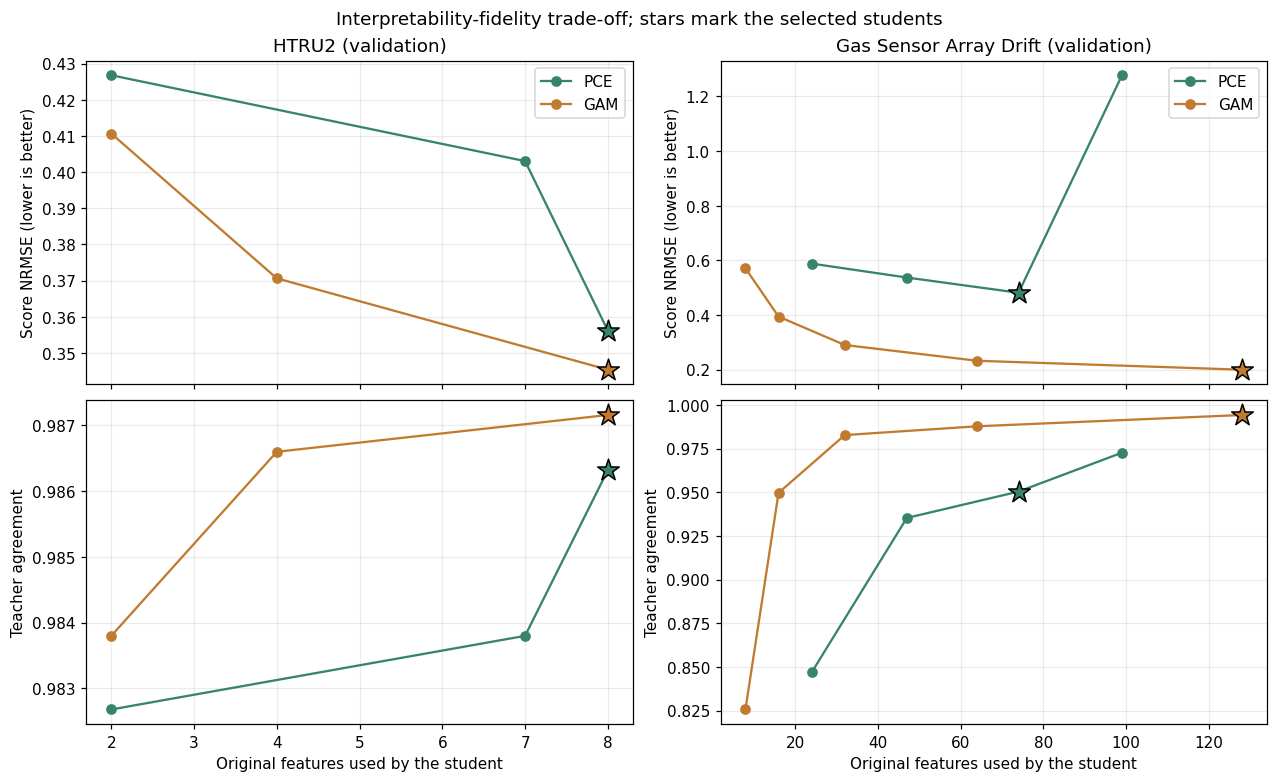

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(11.5, 7), layout='constrained', sharex='col')
for column, (key, d) in enumerate(DATA.items()):
    for method in ('PCE', 'GAM'):
        group = candidates[(candidates['key'] == key) & (candidates['method'] == method)]
        # For the GAM, show the best ridge penalty at each number of features.
        line = group.sort_values('validation_score_nrmse').drop_duplicates('features_used').sort_values('features_used')
        chosen = group[group['selected']]
        for row, metric in enumerate(('validation_score_nrmse', 'validation_teacher_agreement')):
            axes[row, column].plot(line['features_used'], line[metric], 'o-', color=COLORS[method], label=method)
            axes[row, column].scatter(chosen['features_used'], chosen[metric], marker='*', s=220,
                                      color=COLORS[method], edgecolor='black', zorder=4)
    axes[0, column].set_title(f"{d['name']} (validation)")
    axes[0, column].set_ylabel('Score NRMSE (lower is better)')
    axes[1, column].set_ylabel('Teacher agreement')
    axes[1, column].set_xlabel('Original features used by the student')
    axes[0, column].legend()
    for ax in axes[:, column]:
        ax.grid(alpha=0.25)
fig.suptitle('Interpretability-fidelity trade-off; stars mark the selected students')
save_figure(fig, 'fig07_fidelity_vs_complexity')
plt.show()

Reading the trade-off:

* On HTRU2 both students reach their best fidelity with all eight features and the two are close.
  The curve is flat, however: an additive model with only two curves already agrees with the teacher
  on 98.4% of validation cases. Even the best students leave a score NRMSE of about 0.35, roughly 12%
  of the teacher's score variance, so the limit is the form of the students (degree two, or no
  interactions), not their size.
* On the gas data the GAM improves steadily as features are added and needs all 128 curves for its best
  fidelity: fidelity is bought with length, not with a more complicated model form.
* The gas PCE shows that the two fidelity measures can move in opposite directions. Going from 32 to 64
  terms per score increases teacher agreement but makes the score NRMSE much worse, while the median
  absolute error keeps improving. The polynomial fits the bulk better and a small number of extreme
  validation points much worse, which is the expected behaviour of a degree-2 polynomial on
  heavy-tailed inputs. Selection by score NRMSE therefore stops at 32 terms.

### 6.4 What the selected students look like

The HTRU2 students are small enough to be shown in full: the polynomial as its list of terms and the
GAM as one curve per feature.

In [19]:
def term_label(term, labels):
    kind, i, j = term
    return f'p1({labels[i]})' if kind == 1 else f'p2({labels[i]})' if kind == 2 else f'z({labels[i]}) * z({labels[j]})'


rows = []
for key, d in DATA.items():
    model = STUDENTS[key]['PCE']
    for t, term in enumerate(model['terms']):
        for output, score in enumerate(d['score_names']):
            if abs(model['coefficients'][t, output]) > TOL:
                rows.append({'dataset': d['name'], 'score': score, 'term': term_label(term, d['labels']),
                             'order': 2 if term[0] == 3 else 1, 'coefficient': model['coefficients'][t, output]})
pce_terms = save_table(pd.DataFrame(rows), 'pce_coefficients')

htru_terms = pce_terms[pce_terms['dataset'] == 'HTRU2'].copy()
htru_terms['abs_coefficient'] = htru_terms['coefficient'].abs()
print('HTRU2 polynomial: intercept', STUDENTS['htru2']['PCE']['intercept'].round(3),
      f"and {len(htru_terms)} terms; the ten largest are shown.")
display(htru_terms.sort_values('abs_coefficient', ascending=False).head(10)[['term', 'order', 'coefficient']])

HTRU2 polynomial: intercept [-4.881] and 32 terms; the ten largest are shown.


,term,order,coefficient
4,p1(DM SD),1,3.2744
3,p1(Profile kurt),1,2.7076
17,z(Profile mean) * z(Profile skew),2,-2.6621
8,p2(Profile skew),1,-2.6043
0,p1(Profile mean),1,2.1560
5,p1(DM skew),1,1.7979
6,p2(Profile mean),1,-1.7809
20,z(Profile mean) * z(Profile kurt),2,1.6502
28,z(DM SD) * z(DM skew),2,1.3000
9,p2(Profile kurt),1,1.0285


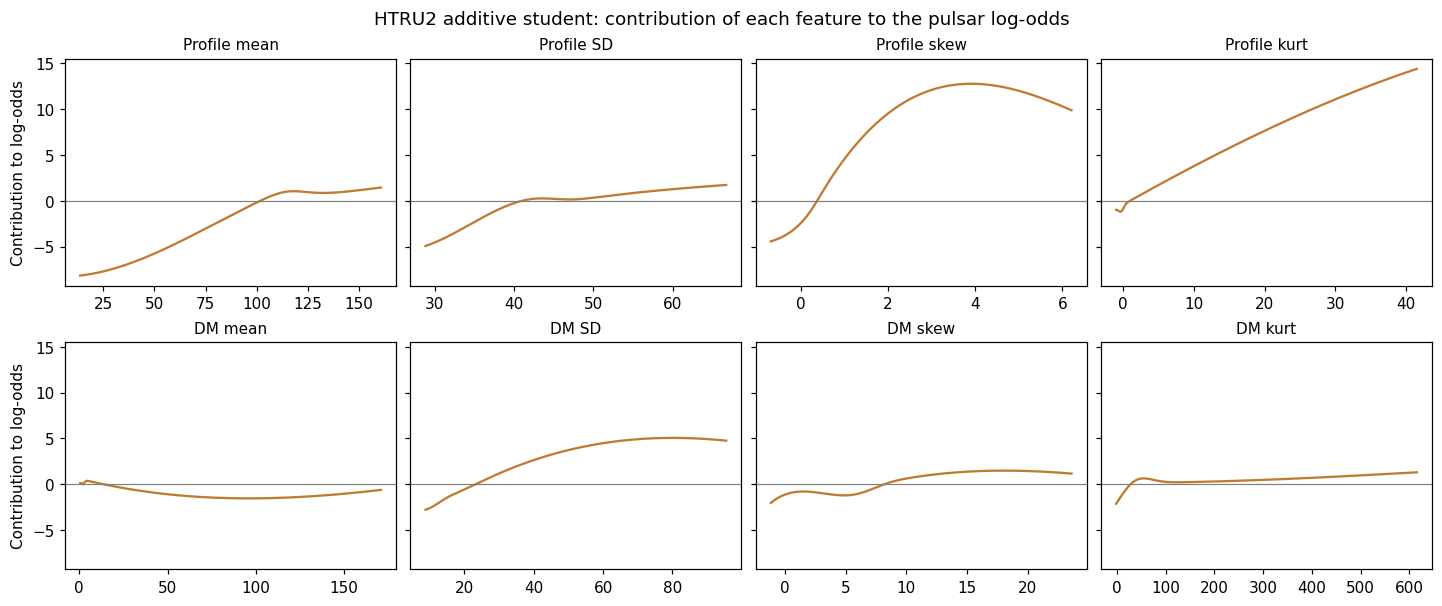

In [20]:
d, model = DATA['htru2'], STUDENTS['htru2']['GAM']
fig, axes = plt.subplots(2, 4, figsize=(13, 5.4), layout='constrained', sharey=True)
for position, (feature, ax) in enumerate(zip(model['selected'], axes.ravel())):
    low, high = np.percentile(d['X_train'][:, feature], [0.5, 99.5])
    grid = np.tile(d['X_train'].mean(axis=0), (200, 1))
    grid[:, feature] = np.linspace(low, high, 200)
    ax.plot(grid[:, feature], gam_components(model, grid)[:, position, 0], color=COLORS['GAM'])
    ax.axhline(0, color='grey', linewidth=0.8)
    ax.set_title(d['labels'][feature], fontsize=10)
for ax in axes[:, 0]:
    ax.set_ylabel('Contribution to log-odds')
fig.suptitle('HTRU2 additive student: contribution of each feature to the pulsar log-odds')
save_figure(fig, 'fig08_htru2_gam_curves')
plt.show()

## 7. Test evaluation

The test partition is used here for the first time. Nothing is refitted or reselected after this point.

Two different questions are kept apart:

* **Accuracy** compares a model with the observed labels.
* **Fidelity** compares a student with the teacher (teacher agreement and score NRMSE).

95% intervals are percentile bootstrap intervals over the test cases (2,000 resamples). They reflect
test-set sampling only, not the variability of the split or of model fitting.

In [21]:
def student_predict(method, model, X):
    return pce_predict(model, X) if method == 'PCE' else gam_predict(model, X)


def bootstrap_interval(per_case, transform=lambda m: m, repeats=2000, seed=SEED):
    """95% percentile bootstrap interval for a (transformed) mean of per-case values."""
    rng = np.random.default_rng(seed)
    index = rng.integers(0, len(per_case), size=(repeats, len(per_case)))
    return np.percentile(transform(per_case[index].mean(axis=1)), [2.5, 97.5])


def rank_correlation(a, b):
    """Spearman correlation; undefined (NaN) if either input is constant."""
    a, b = np.asarray(a), np.asarray(b)
    if np.ptp(a) <= 1e-14 or np.ptp(b) <= 1e-14:
        return np.nan
    return float(spearmanr(a, b).statistic)


metric_rows, class_rows, complexity_rows, case_frames = [], [], [], []
for key, d in DATA.items():
    d['T_test'] = teacher_scores(d['teacher'], d['X_test'])
    d['S_test'] = {'teacher': d['T_test'],
                   **{method: student_predict(method, model, d['X_test']) for method, model in STUDENTS[key].items()}}
    teacher_prob = score_probabilities(d['T_test'])
    teacher_labels = d['classes'][teacher_prob.argmax(axis=1)]
    d['labels_test'] = {}

    # How unusual is each test case relative to the training data?
    train_std = np.where(d['X_train'].std(axis=0) > 1e-12, d['X_train'].std(axis=0), 1.0)
    max_z = np.max(np.abs((d['X_test'] - d['X_train'].mean(axis=0)) / train_std), axis=1)
    outside = ((d['X_test'] < d['X_train'].min(axis=0)) | (d['X_test'] > d['X_train'].max(axis=0))).sum(axis=1)

    for model_name, scores in d['S_test'].items():
        labels = d['classes'][score_probabilities(scores).argmax(axis=1)]
        d['labels_test'][model_name] = labels
        error = scores - d['T_test']
        case_rmse = np.sqrt(np.mean(error ** 2, axis=1))
        correct, agrees = labels == d['y_test'], labels == teacher_labels
        row = {'dataset': d['name'], 'model': model_name, **fidelity_metrics(d, 'test', scores)}
        row['accuracy_ci_low'], row['accuracy_ci_high'] = bootstrap_interval(correct.astype(float))
        if model_name != 'teacher':
            difference = correct.astype(float) - (teacher_labels == d['y_test']).astype(float)
            row['accuracy_minus_teacher'] = difference.mean()
            row['difference_ci_low'], row['difference_ci_high'] = bootstrap_interval(difference)
            row['agreement_ci_low'], row['agreement_ci_high'] = bootstrap_interval(agrees.astype(float))
            row['nrmse_ci_low'], row['nrmse_ci_high'] = bootstrap_interval(
                case_rmse ** 2, transform=lambda m: np.sqrt(m) / d['score_scale'])
        metric_rows.append(row)

        for c in d['classes']:
            members = d['y_test'] == c
            class_rows.append({'dataset': d['name'], 'model': model_name, 'class': d['class_names'][c],
                               'cases': int(members.sum()), 'recall': float(np.mean(labels[members] == c)),
                               'teacher_agreement': float(np.mean(agrees[members])),
                               'score_rmse': float(np.sqrt(np.mean(error[members] ** 2))),
                               'mean_abs_teacher_score': float(np.mean(np.abs(d['T_test'][members])))})
        if model_name == 'teacher':
            continue

        model = STUDENTS[key][model_name]
        counts = pce_complexity(model) if model_name == 'PCE' else {
            'features_used': len(model['selected']), 'effect_components': len(model['selected']),
            'pairwise_components': 0,
            'nonzero_coefficients': int((np.abs(model['spline_coefficients']) > TOL).sum())}
        complexity_rows.append({'dataset': d['name'], 'model': model_name, **counts})
        case_frames.append(pd.DataFrame({
            'dataset': d['name'], 'model': model_name, 'row': d['idx']['test'],
            'true_class': [d['class_names'][c] for c in d['y_test']],
            'teacher_class': [d['class_names'][c] for c in teacher_labels],
            'student_class': [d['class_names'][c] for c in labels],
            'teacher_correct': teacher_labels == d['y_test'], 'student_correct': correct,
            'agrees_with_teacher': agrees, 'score_rmse': case_rmse,
            'teacher_confidence': teacher_prob.max(axis=1),
            'features_outside_training_range': outside, 'max_abs_training_z': max_z}))

test_metrics = save_table(pd.DataFrame(metric_rows), 'test_accuracy_and_fidelity')
per_class = save_table(pd.DataFrame(class_rows), 'test_per_class')
complexity = save_table(pd.DataFrame(complexity_rows), 'student_complexity')
cases = pd.concat(case_frames, ignore_index=True)

### 7.1 Accuracy and fidelity

In [22]:
display(test_metrics[['dataset', 'model', 'accuracy', 'accuracy_ci_low', 'accuracy_ci_high',
                      'balanced_accuracy', 'macro_f1', 'log_loss']])
students_only = test_metrics[test_metrics['model'] != 'teacher']
display(students_only[['dataset', 'model', 'teacher_agreement', 'agreement_ci_low', 'agreement_ci_high',
                       'score_nrmse', 'nrmse_ci_low', 'nrmse_ci_high', 'score_median_abs_error',
                       'accuracy_minus_teacher', 'difference_ci_low', 'difference_ci_high']])
display(complexity)

,dataset,model,accuracy,accuracy_ci_low,accuracy_ci_high,balanced_accuracy,macro_f1,log_loss
0,HTRU2,teacher,0.9763,0.9709,0.9816,0.9417,0.9305,0.0859
1,HTRU2,PCE,0.9799,0.9749,0.9844,0.9190,0.9370,0.0682
2,HTRU2,GAM,0.9771,0.9718,0.9818,0.9175,0.9293,0.0701
3,Gas Sensor Array Drift,teacher,0.9964,0.9939,0.9986,0.9964,0.9965,0.0183
4,Gas Sensor Array Drift,PCE,0.9612,0.9540,0.9684,0.9577,0.9568,0.2024
5,Gas Sensor Array Drift,GAM,0.9935,0.9903,0.9964,0.9933,0.9931,0.0304


,dataset,model,teacher_agreement,agreement_ci_low,agreement_ci_high,score_nrmse,nrmse_ci_low,nrmse_ci_high,score_median_abs_error,accuracy_minus_teacher,difference_ci_low,difference_ci_high
1,HTRU2,PCE,0.9858,0.9816,0.9897,0.3506,0.3408,0.3603,0.8500,0.0036,-0.0003,0.0075
2,HTRU2,GAM,0.9863,0.9824,0.9902,0.3398,0.3300,0.3493,0.7605,0.0008,-0.0031,0.0047
4,Gas Sensor Array Drift,PCE,0.9623,0.9551,0.9691,0.7171,0.4022,1.0510,1.5045,-0.0352,-0.0421,-0.0284
5,Gas Sensor Array Drift,GAM,0.9939,0.9907,0.9968,0.1893,0.1834,0.1952,0.7050,-0.0029,-0.0054,-0.0004


,dataset,model,features_used,effect_components,pairwise_components,nonzero_coefficients
0,HTRU2,PCE,8,32,18,32
1,HTRU2,GAM,8,8,0,48
2,Gas Sensor Array Drift,PCE,74,104,13,160
3,Gas Sensor Array Drift,GAM,128,128,0,3840


Teacher agreement is a coarse measure: it only asks whether the predicted class is the same. Score
NRMSE asks whether the student reproduces the teacher's *function*, which is what an explanation of
the student is supposed to transfer. A student can agree with the teacher on almost every class label
and still differ substantially in its scores, so both are reported.

### 7.2 Results by class

recall                \
model                                     teacher    PCE    GAM   
dataset                class        cases                         
HTRU2                  non_pulsar   3252   0.9840 0.9935 0.9905   
                       pulsar       328    0.8994 0.8445 0.8445   
Gas Sensor Array Drift ethanol      513    0.9961 0.9591 0.9883   
                       ethylene     585    0.9983 0.9949 1.0000   
                       ammonia      328    0.9939 0.9543 0.9939   
                       acetaldehyde 388    0.9948 0.8840 0.9845   
                       acetone      602    0.9950 0.9701 0.9934   
                       toluene      366    1.0000 0.9836 1.0000   

                                          teacher_agreement                \
model                                               teacher    PCE    GAM   
dataset                class        cases                                   
HTRU2                  non_pulsar   3252             1.0000 0.9899 0.9911   
                       pulsar       328              1.0000 0.9451 0.9390   
Gas Sensor Array Drift ethanol      513              1.0000 0.9591 0.9903   
                       ethylene     585              1.0000 0.9966 0.9983   
                       ammonia      328              1.0000 0.9573 0.9970   
                       acetaldehyde 388              1.0000 0.8866 0.9845   
                       acetone      602              1.0000 0.9701 0.9934   
                       toluene      366              1.0000 0.9836 1.0000   

                                          score_rmse                
model                                        teacher    PCE    GAM  
dataset                class        cases                           
HTRU2                  non_pulsar   3252      0.0000 1.2727 1.2501  
                       pulsar       328       0.0000 1.6478 1.4633  
Gas Sensor Array Drift ethanol      513       0.0000 9.8837 1.4777  
                       ethylene     585       0.0000 2.4426 1.1004  
                       ammonia      328       0.0000 2.5945 1.2965  
                       acetaldehyde 388       0.0000 2.9811 1.3855  
                       acetone      602       0.0000 2.8045 1.2545  
                       toluene      366       0.0000 2.4794 1.2171

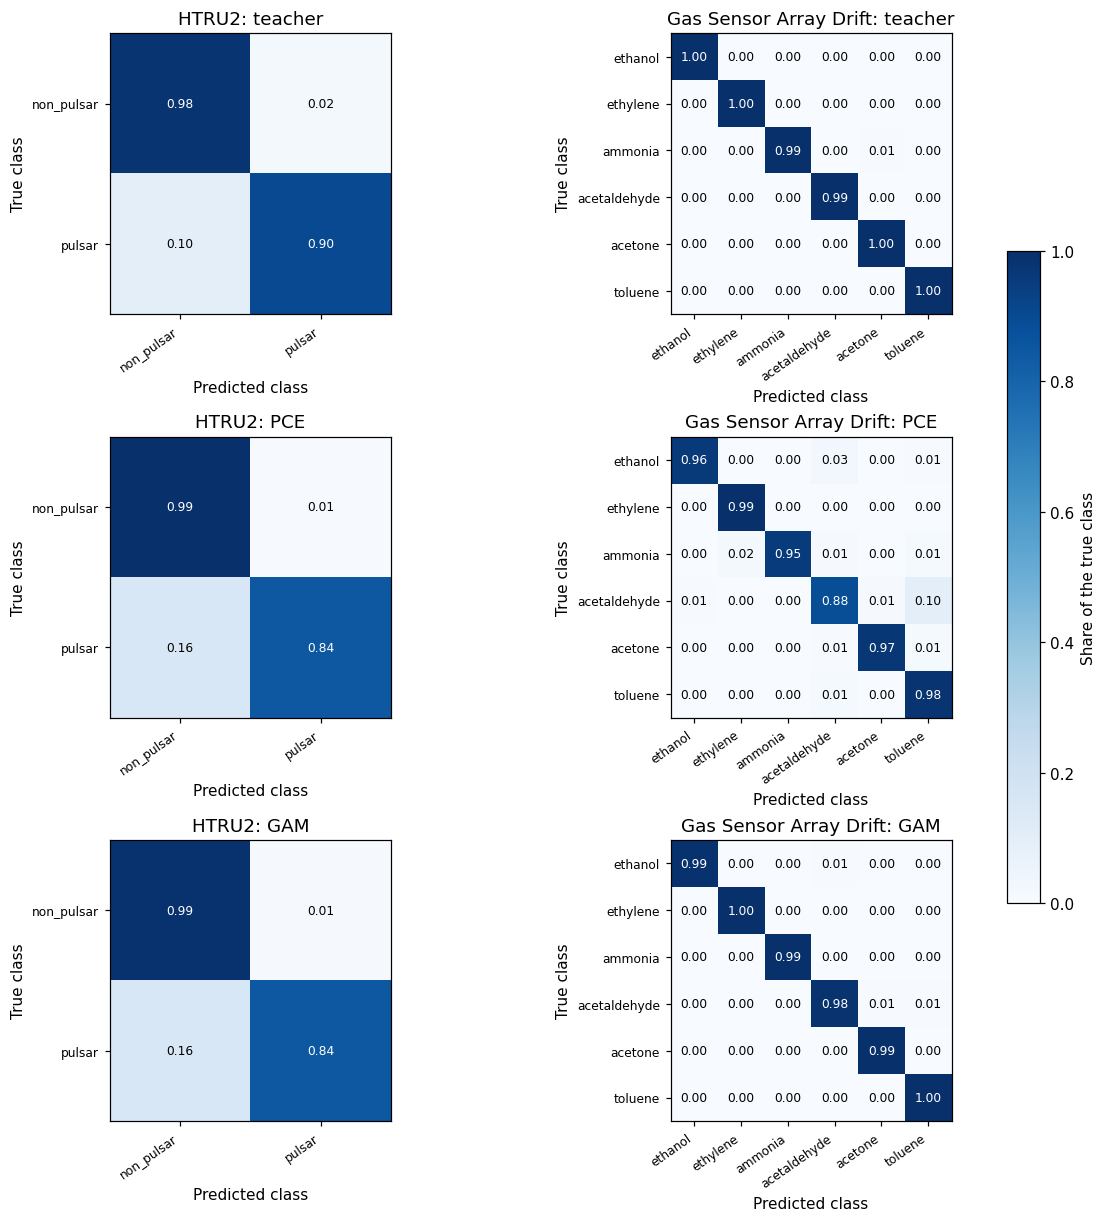

In [23]:
display(per_class.pivot_table(index=['dataset', 'class', 'cases'], columns='model',
                              values=['recall', 'teacher_agreement', 'score_rmse'], sort=False).round(4))

fig, axes = plt.subplots(3, 2, figsize=(11.5, 11), layout='constrained')
for column, (key, d) in enumerate(DATA.items()):
    names = [d['class_names'][c] for c in d['classes']]
    for row, model_name in enumerate(('teacher', 'PCE', 'GAM')):
        matrix = confusion_matrix(d['y_test'], d['labels_test'][model_name], labels=d['classes'], normalize='true')
        ax = axes[row, column]
        image = ax.imshow(matrix, vmin=0, vmax=1, cmap='Blues')
        ax.set_xticks(range(len(names)), names, rotation=35, ha='right', fontsize=8)
        ax.set_yticks(range(len(names)), names, fontsize=8)
        ax.set_xlabel('Predicted class')
        ax.set_ylabel('True class')
        ax.set_title(f"{d['name']}: {model_name}")
        for i, j in itertools.product(range(len(names)), repeat=2):
            ax.text(j, i, f'{matrix[i, j]:.2f}', ha='center', va='center', fontsize=8,
                    color='white' if matrix[i, j] > 0.5 else 'black')
fig.colorbar(image, ax=axes, shrink=0.6, label='Share of the true class')
save_figure(fig, 'fig09_confusion_matrices')
plt.show()

### 7.3 Where and why the students fail

Three diagnostics are used: how the student's errors relate to the teacher's errors, whether fidelity
degrades on unusual inputs (largest absolute training z-score of any feature) and whether it degrades
where the teacher itself is uncertain.

In [24]:
summary_rows, condition_rows, example_frames = [], [], []
for (dataset, model_name), group in cases.groupby(['dataset', 'model'], sort=False):
    summary_rows.append({
        'dataset': dataset, 'model': model_name,
        'teacher_wrong_student_agrees': int((~group['teacher_correct'] & group['agrees_with_teacher']).sum()),
        'teacher_correct_student_wrong': int((group['teacher_correct'] & ~group['student_correct']).sum()),
        'teacher_wrong_student_correct': int((~group['teacher_correct'] & group['student_correct']).sum()),
        'cases_outside_training_range': int((group['features_outside_training_range'] > 0).sum()),
        'spearman_error_vs_extremeness': rank_correlation(group['score_rmse'], group['max_abs_training_z'])})

    extreme = group['max_abs_training_z'] > group['max_abs_training_z'].quantile(0.95)
    uncertain = group['teacher_confidence'] < 0.9
    for condition, mask in [('typical inputs', ~extreme), ('most extreme 5% of inputs', extreme),
                            ('teacher confident (p >= 0.9)', ~uncertain), ('teacher uncertain (p < 0.9)', uncertain)]:
        subset = group[mask]
        condition_rows.append({'dataset': dataset, 'model': model_name, 'condition': condition,
                               'cases': len(subset), 'teacher_agreement': subset['agrees_with_teacher'].mean(),
                               'score_rmse': float(np.sqrt(np.mean(subset['score_rmse'] ** 2)))})

    example_frames += [group.nlargest(3, 'score_rmse').assign(selected_for='largest score error'),
                       group[~group['agrees_with_teacher']].nlargest(3, 'teacher_confidence')
                       .assign(selected_for='most confident disagreement')]

failure_summary = save_table(pd.DataFrame(summary_rows), 'failure_summary')
failure_conditions = save_table(pd.DataFrame(condition_rows), 'failure_by_condition')
failure_examples = save_table(pd.concat(example_frames, ignore_index=True), 'failure_examples')
display(failure_summary)
display(failure_conditions)
display(failure_examples[['dataset', 'model', 'selected_for', 'true_class', 'teacher_class', 'student_class',
                          'score_rmse', 'teacher_confidence', 'features_outside_training_range',
                          'max_abs_training_z']])

,dataset,model,teacher_wrong_student_agrees,teacher_correct_student_wrong,teacher_wrong_student_correct,cases_outside_training_range,spearman_error_vs_extremeness
0,HTRU2,PCE,53,19,32,3,0.0560
1,HTRU2,GAM,59,23,26,3,0.0838
2,Gas Sensor Array Drift,PCE,4,99,1,22,-0.0424
3,Gas Sensor Array Drift,GAM,3,10,2,22,0.0258


,dataset,model,condition,cases,teacher_agreement,score_rmse
0,HTRU2,PCE,typical inputs,3401,0.9862,1.3095
1,HTRU2,PCE,most extreme 5% of inputs,179,0.9777,1.3505
2,HTRU2,PCE,teacher confident (p >= 0.9),3384,0.9976,1.2050
3,HTRU2,PCE,teacher uncertain (p < 0.9),196,0.7806,2.5203
4,HTRU2,GAM,typical inputs,3401,0.9868,1.2707
5,HTRU2,GAM,most extreme 5% of inputs,179,0.9777,1.2799
6,HTRU2,GAM,teacher confident (p >= 0.9),3384,0.9976,1.1876
7,HTRU2,GAM,teacher uncertain (p < 0.9),196,0.7908,2.2724
8,Gas Sensor Array Drift,PCE,typical inputs,2642,0.9663,2.6394
9,Gas Sensor Array Drift,PCE,most extreme 5% of inputs,140,0.8857,18.4853


,dataset,model,selected_for,true_class,teacher_class,student_class,score_rmse,teacher_confidence,features_outside_training_range,max_abs_training_z
0,HTRU2,PCE,largest score error,non_pulsar,pulsar,non_pulsar,6.0699,0.7509,0,1.6321
1,HTRU2,PCE,largest score error,pulsar,pulsar,non_pulsar,5.7469,0.9591,0,1.6494
2,HTRU2,PCE,largest score error,non_pulsar,pulsar,non_pulsar,5.3460,0.7242,0,0.6351
3,HTRU2,PCE,most confident disagreement,non_pulsar,pulsar,non_pulsar,3.9643,0.9771,0,0.9585
4,HTRU2,PCE,most confident disagreement,pulsar,pulsar,non_pulsar,3.9276,0.9628,0,4.2483
5,HTRU2,PCE,most confident disagreement,pulsar,pulsar,non_pulsar,5.7469,0.9591,0,1.6494
6,HTRU2,GAM,largest score error,non_pulsar,pulsar,non_pulsar,6.6666,0.7509,0,1.6321
7,HTRU2,GAM,largest score error,non_pulsar,non_pulsar,non_pulsar,5.9573,0.5628,0,1.2854
8,HTRU2,GAM,largest score error,non_pulsar,non_pulsar,non_pulsar,5.8237,0.6399,0,1.9510
9,HTRU2,GAM,most confident disagreement,pulsar,pulsar,non_pulsar,4.6363,0.9591,0,1.6494


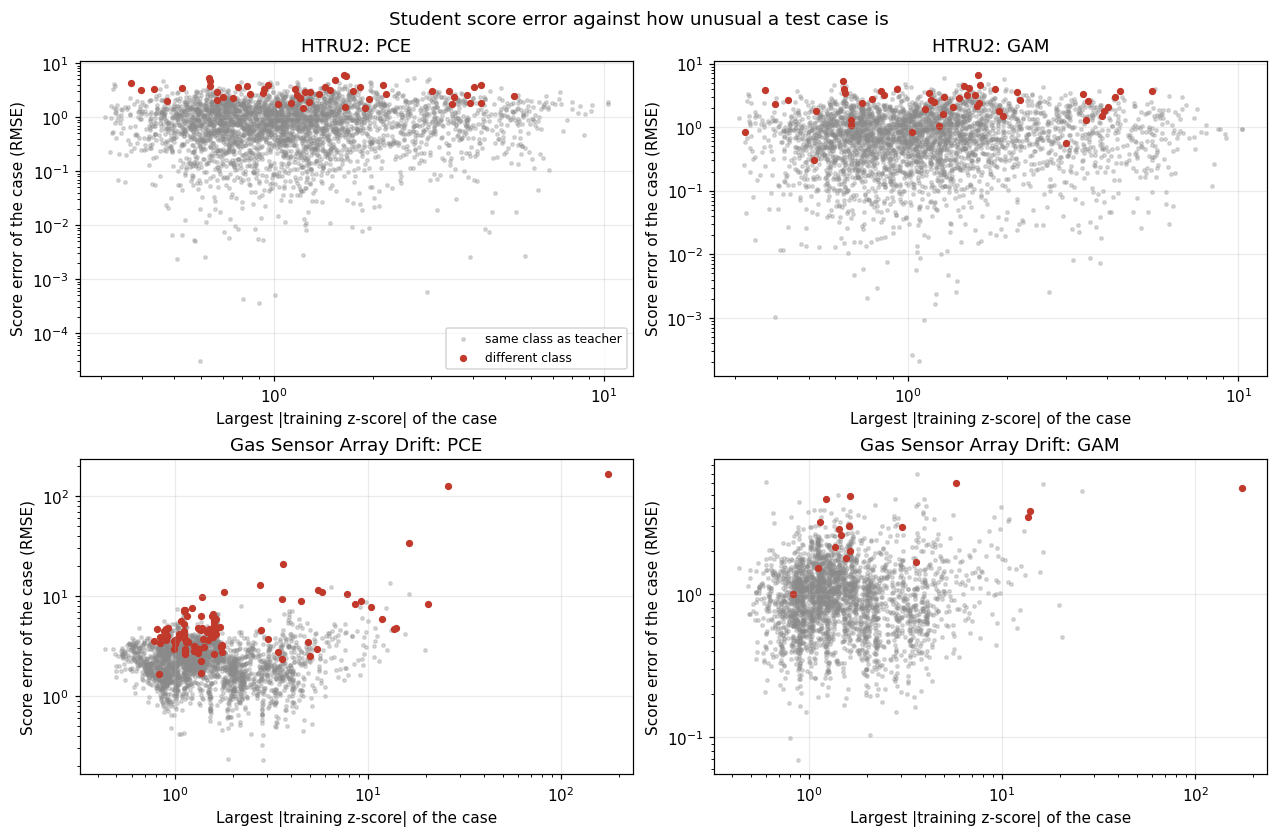

In [25]:
fig, axes = plt.subplots(2, 2, figsize=(11.5, 7.5), layout='constrained')
for ax, ((dataset, model_name), group) in zip(axes.ravel(), cases.groupby(['dataset', 'model'], sort=False)):
    agree = group['agrees_with_teacher']
    ax.scatter(group.loc[agree, 'max_abs_training_z'], group.loc[agree, 'score_rmse'], s=5, alpha=0.3,
               color='#8a8a8a', label='same class as teacher')
    ax.scatter(group.loc[~agree, 'max_abs_training_z'], group.loc[~agree, 'score_rmse'], s=14,
               color='#c0392b', label='different class')
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.set_title(f'{dataset}: {model_name}')
    ax.set_xlabel('Largest |training z-score| of the case')
    ax.set_ylabel('Score error of the case (RMSE)')
    ax.grid(alpha=0.25)
axes[0, 0].legend(fontsize=8)
fig.suptitle('Student score error against how unusual a test case is')
save_figure(fig, 'fig10_error_vs_extremeness')
plt.show()

What the diagnostics show:

* **Inherited errors:** On HTRU2 most student errors are the teacher's errors: the students repeat 53
  (PCE) and 59 (GAM) of the teacher's mistakes and add only 19 and 23 of their own. A faithful student
  copies its teacher, so fidelity is not accuracy. On the gas data the teacher is almost always right
  and the PCE adds 99 errors of its own.
* **Decision boundary:** Where the teacher is confident (p >= 0.9), the students agree with it on at
  least 99.6% of cases (96.6% for the gas PCE). Where the teacher is uncertain, agreement falls to
  62-79%: near the decision boundary a small score error is enough to change the predicted class.
* **Extrapolation:** The rank correlation between score error and input extremeness is close to zero
  for every student, so over the bulk of the data unusual inputs are not fitted worse. The exception is
  the tail of the gas PCE: on the 5% most extreme inputs its score RMSE is 18.5 against 2.6 elsewhere
  and its class agreement drops from 96.6% to 88.6%. A degree-2 polynomial grows quadratically away
  from the training bulk, whereas the output of a tree ensemble is bounded; the GAM, which
  extrapolates linearly, degrades far less (1.8 against 1.3). A few such cases dominate the squared
  error, which is why the bootstrap interval of the gas PCE's NRMSE is so wide (0.40 to 1.05) and why
  its test value (0.72) is far from its validation value (0.48).
* **Saturated scores:** The teacher's scores are largest for the reference class ethanol (mean absolute
  score 10.7 against 3.0-3.6 for the other gases): boosted trees produce very large, flat log-odds
  where they are certain. The PCE's score RMSE is 9.9 in that class against 2.4-3.0 in the others,
  while the GAM's error is uniform (1.1-1.5).

## 8. Explanations

This section asks whether the two students explain a prediction in the same way, and whether either
agrees with a post-hoc explanation of the teacher.

**Common definition.** All three explanations are Shapley-value attributions of the same quantity
(each log-odds score) with the same treatment of "missing" features: a missing feature is drawn from
its training marginal, independently of the others (product-of-marginals reference). With a common
definition, differences between explanations reflect differences between the models and estimation
noise, not different conventions.

* **Students (built in).** For the additive model the Shapley value of a feature is exactly its centred
  curve value. For the polynomial, a main-effect term belongs to its feature and a product term
  $z_i z_j$ is split equally between $i$ and $j$. Both follow in closed form from the fitted model.
* **Teacher (post hoc).** The tree ensemble has no closed form under this reference, so its Shapley
  values are estimated by Monte Carlo permutation sampling.

Explanations are computed for a class-stratified random sample of test cases; global importance is the
mean absolute attribution, weighted back to the test class proportions.

In [26]:
CASES_PER_CLASS = {'htru2': 12, 'gas': 4}

EXPLAINED, rows = {}, []
for number, (key, d) in enumerate(DATA.items()):
    rng = np.random.default_rng(SEED + 401 + number)
    chosen, weights = [], []
    for c in d['classes']:
        eligible = np.flatnonzero(d['y_test'] == c)
        take = min(CASES_PER_CLASS[key], len(eligible))
        chosen += rng.choice(eligible, size=take, replace=False).tolist()
        weights += [len(eligible) / len(d['y_test']) / take] * take       # restores the class proportions
    order = np.argsort(chosen)
    positions, weights = np.asarray(chosen)[order], np.asarray(weights)[order]
    assert np.isclose(weights.sum(), 1)
    EXPLAINED[key] = {'positions': positions, 'X': d['X_test'][positions], 'weights': weights,
                      'top_k': min(10, max(1, d['X'].shape[1] // 2))}
    rows += [{'dataset': d['name'], 'row': int(d['idx']['test'][p]),
              'true_class': d['class_names'][d['y_test'][p]], 'weight': w} for p, w in zip(positions, weights)]
save_table(pd.DataFrame(rows), 'explained_cases')
print({DATA[key]['name']: len(e['positions']) for key, e in EXPLAINED.items()}, 'explained test cases')

{'HTRU2': 24, 'Gas Sensor Array Drift': 24} explained test cases


### 8.1 Built-in attributions of the students

In [27]:
def pce_attributions(model, X):
    """Exact Shapley values of the polynomial under the product-of-marginals reference."""
    design = pce_design(X, model['basis'], model['terms'])
    phi = np.zeros((len(X), X.shape[1], model['coefficients'].shape[1]))
    for t, (kind, i, j) in enumerate(model['terms']):
        value = design[:, t, None] * model['coefficients'][t][None, :]
        if kind == 3:                         # product term: shared equally by its two features
            phi[:, i] += 0.5 * value
            phi[:, j] += 0.5 * value
        else:                                 # main-effect term: belongs to its feature
            phi[:, i] += value
    return phi, model['intercept']


def gam_attributions(model, X):
    """Exact Shapley values of the additive model: the centred curve of each feature."""
    phi = np.zeros((len(X), X.shape[1], model['centering'].shape[1]))
    phi[:, model['selected']] = gam_components(model, X)
    return phi, model['baseline']


EXACT = {}
for key, e in EXPLAINED.items():
    EXACT[key] = {}
    for method, attribute in (('PCE', pce_attributions), ('GAM', gam_attributions)):
        phi, baseline = attribute(STUDENTS[key][method], e['X'])
        # Local accuracy: baseline plus attributions equals the student's score.
        assert np.allclose(baseline + phi.sum(axis=1), student_predict(method, STUDENTS[key][method], e['X']), atol=1e-8)
        EXACT[key][method] = phi

### 8.2 Permutation Shapley estimator for the teacher

For one random feature order, start from background rows drawn from the reference distribution and
switch the features to the explained case's values one at a time; the change in the average model
output at each step is that feature's contribution. Averaging over orders gives the Shapley value.
Each order is paired with its reverse (antithetic sampling) to reduce variance.

The estimator is first checked on a function whose Shapley values are known exactly.

In [28]:
def path_contributions(predict, X, background, order, chunk=4):
    """Contributions of each feature along one feature order, averaged over the background rows."""
    n, n_features = X.shape
    B = len(background)
    baseline = np.asarray(predict(background)).reshape(B, -1).mean(axis=0)
    phi = np.empty((n, n_features, len(baseline)))
    for start in range(0, n, chunk):
        block = X[start:start + chunk]
        m = len(block)
        # paths[case, step, background row, feature]: step s has the first s features of `order` switched.
        paths = np.empty((m, n_features + 1, B, n_features))
        paths[:, 0] = background[None]
        for step, feature in enumerate(order):
            paths[:, step + 1] = paths[:, step]
            paths[:, step + 1, :, feature] = block[:, feature, None]
        scores = np.asarray(predict(paths.reshape(-1, n_features))).reshape(m, n_features + 1, B, -1).mean(axis=2)
        phi[start:start + m, np.asarray(order)] = np.diff(scores, axis=1)
        # Local accuracy up to floating-point error: the contributions sum to prediction minus baseline.
        tolerance = 1e-8 * max(1.0, float(np.abs(scores).max()))
        assert np.allclose(baseline + phi[start:start + m].sum(axis=1),
                           np.asarray(predict(block)).reshape(m, -1), atol=tolerance)
    return phi, baseline


# Known case: f = 0.7 + x0 - 2 x1 + 0.5 x2 + 3 x0 x1 with a symmetric background on {-1, 1}^3.
toy_background = np.asarray(list(itertools.product([-1.0, 1.0], repeat=3)))
toy_X = np.array([[0.3, -0.5, 0.7], [-0.2, 0.9, -0.1]])
toy = lambda A: (0.7 + A[:, 0] - 2 * A[:, 1] + 0.5 * A[:, 2] + 3 * A[:, 0] * A[:, 1])[:, None]
forward, toy_baseline = path_contributions(toy, toy_X, toy_background, [2, 0, 1])
reverse, _ = path_contributions(toy, toy_X, toy_background, [1, 0, 2])
expected = np.column_stack([toy_X[:, 0] + 1.5 * toy_X[:, 0] * toy_X[:, 1],
                            -2 * toy_X[:, 1] + 1.5 * toy_X[:, 0] * toy_X[:, 1],
                            0.5 * toy_X[:, 2]])[:, :, None]
assert np.allclose((forward + reverse) / 2, expected, atol=1e-12) and np.allclose(toy_baseline, 0.7)
print('Estimator reproduces the exact Shapley values of the test function.')

Estimator reproduces the exact Shapley values of the test function.


The same random feature orders and background rows are applied to the teacher and, as a control, to
both students. The students' exact attributions are known (Section 8.1), so the control measures
directly how much disagreement the estimator's sampling noise produces on its own.

In [29]:
PERMUTATION_PAIRS = 8          # forward/reverse order pairs
BACKGROUND_ROWS = 16           # reference rows per pair

SAMPLED = {}
for number, (key, d) in enumerate(DATA.items()):
    rng = np.random.default_rng(SEED + 701 + number)
    X, n_features = EXPLAINED[key]['X'], d['X'].shape[1]
    predictors = {'teacher': lambda A, t=d['teacher']: teacher_scores(t, A),
                  'PCE': lambda A, m=STUDENTS[key]['PCE']: pce_predict(m, A),
                  'GAM': lambda A, m=STUDENTS[key]['GAM']: gam_predict(m, A)}
    estimates = {name: [] for name in predictors}
    for _ in range(PERMUTATION_PAIRS):
        # Independent row indices per feature give a draw from the product of the training marginals.
        draw = rng.integers(0, len(d['X_train']), size=(BACKGROUND_ROWS, n_features))
        background = d['X_train'][draw, np.arange(n_features)[None, :]]
        order = rng.permutation(n_features)
        for name, predict in predictors.items():
            forward, _ = path_contributions(predict, X, background, order)
            reverse, _ = path_contributions(predict, X, background, order[::-1])
            estimates[name].append((forward + reverse) / 2)
    SAMPLED[key] = {name: np.stack(values) for name, values in estimates.items()}      # (pairs, cases, features, scores)
    print(f"{d['name']}: {PERMUTATION_PAIRS} permutation pairs for {len(X)} cases")

# Explanations compared below: sampled for the teacher, exact for the students.
ATTRIBUTIONS = {key: {'teacher': SAMPLED[key]['teacher'].mean(axis=0), **EXACT[key]} for key in DATA}

HTRU2: 8 permutation pairs for 24 cases
Gas Sensor Array Drift: 8 permutation pairs for 24 cases


### 8.3 Agreement measures and estimator reliability

Four measures compare two sets of attributions, each computed per score and then averaged over scores:

* **global rank correlation**: Spearman correlation of the global importance rankings;
* **top-k overlap**: Jaccard index of the two sets of k most important features (k = 4 for HTRU2, 10 for gas);
* **local cosine**: mean cosine similarity of the signed attribution vectors of individual cases
  (1 = same direction, 0 = unrelated);
* **local relative L1**: mean absolute difference of the attribution vectors relative to their average
  size (0 = identical).

In [30]:
def global_importance(phi, weights):
    """Weighted mean absolute attribution, shape (features, scores)."""
    return np.sum(weights[:, None, None] * np.abs(phi), axis=0)


def top_features(values, k):
    """Indices of the k largest values; ties are broken by feature index."""
    return np.lexsort((np.arange(len(values)), -np.asarray(values)))[:k]


def top_jaccard(a, b, k):
    A, B = set(top_features(a, k)), set(top_features(b, k))
    return len(A & B) / len(A | B)


def agreement(phi_a, phi_b, weights, k):
    """Agreement of two attribution arrays (cases, features, scores); one row per score."""
    global_a, global_b = global_importance(phi_a, weights), global_importance(phi_b, weights)
    rows = []
    for output in range(phi_a.shape[2]):
        a, b = phi_a[:, :, output], phi_b[:, :, output]
        norm = np.linalg.norm(a, axis=1) * np.linalg.norm(b, axis=1)
        cosine = np.divide(np.sum(a * b, axis=1), norm, out=np.full(len(a), np.nan), where=norm > 1e-12)
        valid = np.isfinite(cosine)
        size = 0.5 * (np.abs(a).sum(axis=1) + np.abs(b).sum(axis=1))
        relative_l1 = np.divide(np.abs(a - b).sum(axis=1), size, out=np.zeros(len(a)), where=size > 1e-12)
        rows.append({'global_rank_spearman': rank_correlation(global_a[:, output], global_b[:, output]),
                     'global_top_k_jaccard': top_jaccard(global_a[:, output], global_b[:, output], k),
                     'local_cosine': float(np.sum(weights[valid] * cosine[valid]) / weights[valid].sum())
                                     if valid.any() else np.nan,
                     'local_relative_l1': float(np.sum(weights * relative_l1))})
    return pd.DataFrame(rows)


MEASURES = ['global_rank_spearman', 'global_top_k_jaccard', 'local_cosine', 'local_relative_l1']

stability_rows, control_rows = [], []
for key, d in DATA.items():
    e, pairs = EXPLAINED[key], SAMPLED[key]['teacher']
    half = len(pairs) // 2
    first, second = pairs[:half].mean(axis=0), pairs[half:].mean(axis=0)
    standard_error = pairs.std(axis=0, ddof=1) / np.sqrt(len(pairs))
    for output, score in enumerate(d['score_names']):
        a = global_importance(first, e['weights'])[:, output]
        b = global_importance(second, e['weights'])[:, output]
        magnitude = np.sum(e['weights'][:, None] * np.abs(ATTRIBUTIONS[key]['teacher'][:, :, output]))
        stability_rows.append({'dataset': d['name'], 'score': score, 'explained_cases': len(e['weights']),
                               'half_split_rank_spearman': rank_correlation(a, b),
                               'half_split_top_k_jaccard': top_jaccard(a, b, e['top_k']),
                               'mc_standard_error_share': float(np.sum(e['weights'][:, None] * standard_error[:, :, output]) / magnitude)})
    # Control: the estimator applied to a student against that student's exact attributions.
    for method in ('PCE', 'GAM'):
        result = agreement(SAMPLED[key][method].mean(axis=0), EXACT[key][method], e['weights'], e['top_k'])
        control_rows.append({'dataset': d['name'], 'model': method, **result[MEASURES].mean().to_dict()})

stability = save_table(pd.DataFrame(stability_rows), 'shapley_sampling_stability')
estimator_control = save_table(pd.DataFrame(control_rows), 'shapley_estimator_control')
display(stability)
display(estimator_control)

,dataset,score,explained_cases,half_split_rank_spearman,half_split_top_k_jaccard,mc_standard_error_share
0,HTRU2,pulsar vs non_pulsar,24,0.9762,1.0000,0.1848
1,Gas Sensor Array Drift,ethylene vs ethanol,24,0.9923,1.0000,0.1181
2,Gas Sensor Array Drift,ammonia vs ethanol,24,0.9928,0.8182,0.1281
3,Gas Sensor Array Drift,acetaldehyde vs ethanol,24,0.9944,1.0000,0.1343
4,Gas Sensor Array Drift,acetone vs ethanol,24,0.9909,1.0000,0.1204
5,Gas Sensor Array Drift,toluene vs ethanol,24,0.9936,0.8182,0.1271


,dataset,model,global_rank_spearman,global_top_k_jaccard,local_cosine,local_relative_l1
0,HTRU2,PCE,0.9762,0.6000,0.9880,0.1597
1,HTRU2,GAM,0.9762,1.0000,0.9919,0.1302
2,Gas Sensor Array Drift,PCE,1.0000,1.0000,0.9882,0.1342
3,Gas Sensor Array Drift,GAM,0.9991,1.0000,0.9957,0.0845


The first table compares the teacher's global rankings obtained from two independent halves of the
permutation pairs: they correlate at 0.97 or more, although the Monte Carlo standard error of a single
attribution is 12-18% of its typical size. The second table is the noise floor of the whole comparison:
the agreement reached when the *same* model is explained once by sampling and once exactly (local
cosine of 0.98 or more). Agreement between two different models cannot be expected to exceed these
values, and only shortfalls well below them can be attributed to the models rather than to the
estimator. With eight features and k = 4, the top-k overlap is a coarse measure: one swap between two
features of similar importance already lowers it to 0.6.

### 8.4 Do the explanations agree?

,dataset,comparison,global_rank_spearman,global_top_k_jaccard,local_cosine,local_relative_l1
0,HTRU2,PCE vs GAM,0.8571,0.6000,0.8409,0.6726
1,HTRU2,PCE vs teacher,0.9762,1.0000,0.7161,0.9243
2,HTRU2,GAM vs teacher,0.8810,0.6000,0.7598,0.8828
3,Gas Sensor Array Drift,PCE vs GAM,0.0406,0.1520,0.3089,1.6338
4,Gas Sensor Array Drift,PCE vs teacher,0.2867,0.1928,0.3406,1.6878
5,Gas Sensor Array Drift,GAM vs teacher,0.1320,0.1797,0.3523,1.6938


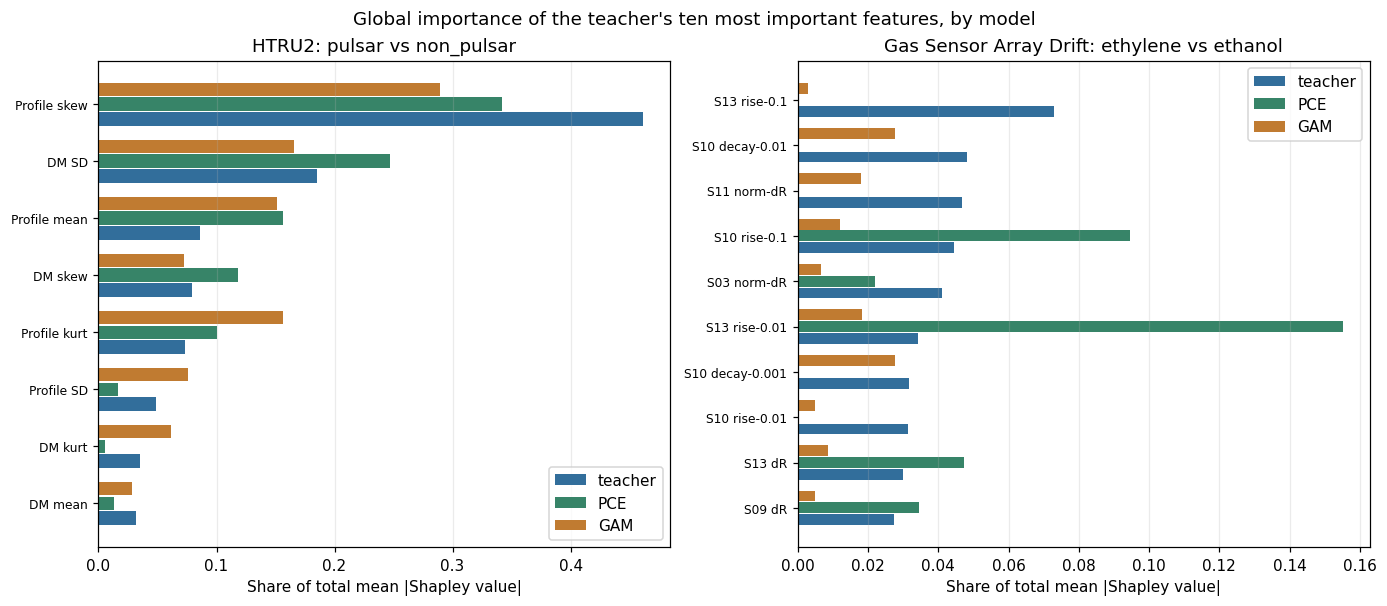

In [31]:
rows = []
for key, d in DATA.items():
    e = EXPLAINED[key]
    for a, b in (('PCE', 'GAM'), ('PCE', 'teacher'), ('GAM', 'teacher')):
        result = agreement(ATTRIBUTIONS[key][a], ATTRIBUTIONS[key][b], e['weights'], e['top_k'])
        rows.append(result.assign(dataset=d['name'], comparison=f'{a} vs {b}', score=d['score_names']))
agreement_per_score = save_table(pd.concat(rows, ignore_index=True)[['dataset', 'comparison', 'score'] + MEASURES],
                                 'explanation_agreement_per_score')
explanation_agreement = save_table(
    agreement_per_score.groupby(['dataset', 'comparison'], sort=False)[MEASURES].mean().reset_index(),
    'explanation_agreement')
display(explanation_agreement)

rows = []
for key, d in DATA.items():
    importance = {name: global_importance(phi, EXPLAINED[key]['weights']) for name, phi in ATTRIBUTIONS[key].items()}
    d['importance'] = importance
    for name, values in importance.items():
        for output, score in enumerate(d['score_names']):
            rows += [{'dataset': d['name'], 'model': name, 'score': score, 'feature': label,
                      'mean_abs_shapley': values[j, output]} for j, label in enumerate(d['labels'])]
save_table(pd.DataFrame(rows), 'shapley_global_importance')

fig, axes = plt.subplots(1, 2, figsize=(12.5, 5.4), layout='constrained')
for ax, (key, d) in zip(axes, DATA.items()):
    shown = top_features(d['importance']['teacher'][:, 0], min(10, d['X'].shape[1]))[::-1]
    y = np.arange(len(shown))
    for offset, name in zip((-0.26, 0, 0.26), ('teacher', 'PCE', 'GAM')):
        values = d['importance'][name][:, 0]
        ax.barh(y + offset, values[shown] / values.sum(), height=0.24, color=COLORS[name], label=name)
    ax.set_yticks(y, [d['labels'][j] for j in shown], fontsize=8)
    ax.set_xlabel('Share of total mean |Shapley value|')
    ax.set_title(f"{d['name']}: {d['score_names'][0]}")
    ax.grid(axis='x', alpha=0.25)
    ax.legend()
fig.suptitle("Global importance of the teacher's ten most important features, by model")
save_figure(fig, 'fig11_shapley_importance')
plt.show()

* **HTRU2:** The three explanations broadly agree. The global rankings correlate at 0.86 to 0.98 and the
  attribution vectors of individual cases point in similar directions (cosine 0.72 to 0.84). These
  values are still clearly below the estimator control (0.99), so the remaining differences belong to
  the models. The two students agree with each other more than either agrees with the teacher.
* **Gas:** Agreement is low on every measure (rank correlation 0.04 to 0.29, local cosine 0.31 to 0.35),
  even for the GAM, which predicts the same class as the teacher on 99.4% of the test cases. High
  predictive fidelity did not carry over to the explanation.

### 8.5 Sobol' indices of the students

Sobol' indices describe a model globally: the share of the variance of its output that is due to each
feature, under the product-of-marginals reference.

* **PCE:** The basis is orthonormal under that reference, so the variance is the sum of the squared
  coefficients. A feature's first-order index collects its main-effect terms; its total index adds every
  product term it takes part in. No sampling is needed.
* **GAM:** With no interactions, first-order and total indices coincide and equal the variance of each
  feature's curve divided by the sum of these variances.

These indices answer a different question from the Shapley importances above (variance shares of the
student, not average attribution sizes), so they are compared between the two students only.

,dataset,score,first_order_rank_spearman,total_effect_rank_spearman,pce_interaction_variance_share
0,HTRU2,pulsar vs non_pulsar,0.7857,0.6667,0.2577
1,Gas Sensor Array Drift,ethylene vs ethanol,0.0552,0.1162,0.0806
2,Gas Sensor Array Drift,ammonia vs ethanol,0.0229,0.0476,0.0343
3,Gas Sensor Array Drift,acetaldehyde vs ethanol,-0.0698,-0.0199,0.0915
4,Gas Sensor Array Drift,acetone vs ethanol,-0.0848,-0.0372,0.0043
5,Gas Sensor Array Drift,toluene vs ethanol,0.0973,0.1343,0.0845


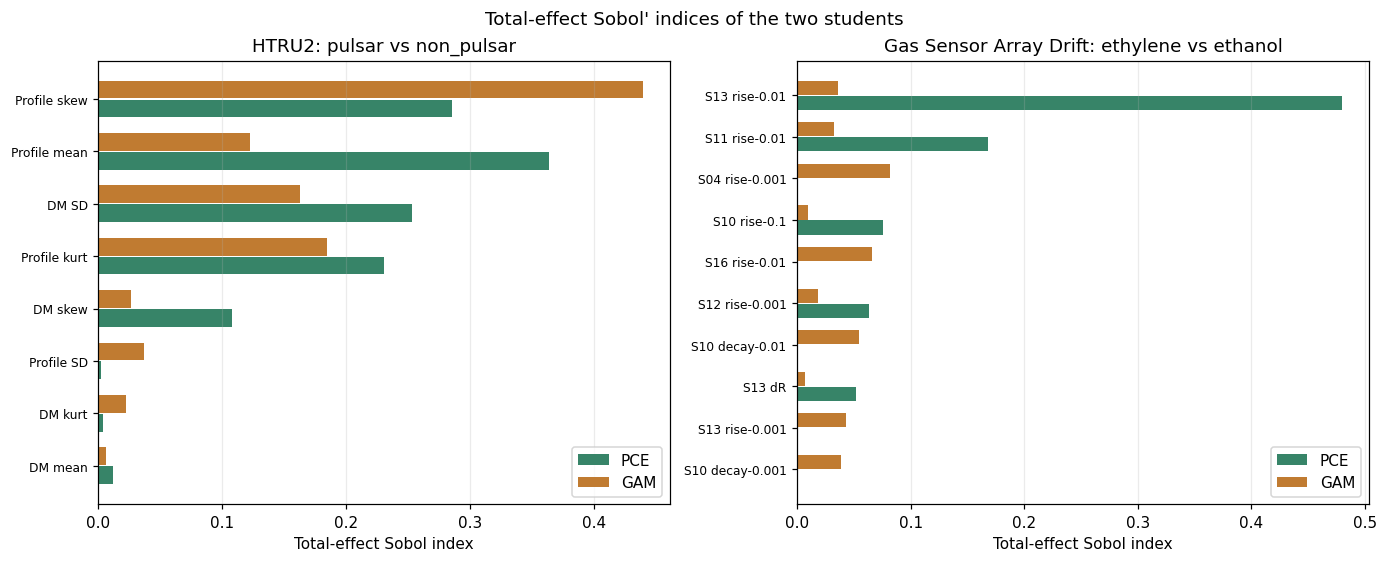

In [32]:
sobol_rows, sobol_agreement_rows = [], []
for key, d in DATA.items():
    n_features, n_scores = d['X'].shape[1], len(d['score_names'])
    pce = STUDENTS[key]['PCE']
    squared = pce['coefficients'] ** 2
    main, total, pairwise = np.zeros((n_features, n_scores)), np.zeros((n_features, n_scores)), np.zeros(n_scores)
    for t, (kind, i, j) in enumerate(pce['terms']):
        if kind == 3:
            total[i] += squared[t]
            total[j] += squared[t]
            pairwise += squared[t]
        else:
            main[i] += squared[t]
            total[i] += squared[t]
    variance = squared.sum(axis=0)
    assert np.allclose(main.sum(axis=0) + pairwise, variance)             # variance partition
    indices = {'PCE': (main / variance, total / variance)}

    curve_variance = np.var(gam_attributions(STUDENTS[key]['GAM'], d['X_train'])[0], axis=0)
    gam_share = curve_variance / curve_variance.sum(axis=0)
    indices['GAM'] = (gam_share, gam_share)
    d['sobol_total'] = {name: values[1] for name, values in indices.items()}

    for name, (first_order, total_effect) in indices.items():
        for output, score in enumerate(d['score_names']):
            sobol_rows += [{'dataset': d['name'], 'model': name, 'score': score, 'feature': label,
                            'first_order': first_order[j, output], 'total_effect': total_effect[j, output]}
                           for j, label in enumerate(d['labels'])]
    for output, score in enumerate(d['score_names']):
        sobol_agreement_rows.append({
            'dataset': d['name'], 'score': score,
            'first_order_rank_spearman': rank_correlation(indices['PCE'][0][:, output], gam_share[:, output]),
            'total_effect_rank_spearman': rank_correlation(indices['PCE'][1][:, output], gam_share[:, output]),
            'pce_interaction_variance_share': pairwise[output] / variance[output]})

save_table(pd.DataFrame(sobol_rows), 'sobol_indices')
sobol_agreement = save_table(pd.DataFrame(sobol_agreement_rows), 'sobol_agreement')
display(sobol_agreement)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 5), layout='constrained')
for ax, (key, d) in zip(axes, DATA.items()):
    pce_total, gam_total = d['sobol_total']['PCE'][:, 0], d['sobol_total']['GAM'][:, 0]
    shown = top_features(np.maximum(pce_total, gam_total), min(10, len(pce_total)))[::-1]
    y = np.arange(len(shown))
    ax.barh(y - 0.18, pce_total[shown], height=0.34, color=COLORS['PCE'], label='PCE')
    ax.barh(y + 0.18, gam_total[shown], height=0.34, color=COLORS['GAM'], label='GAM')
    ax.set_yticks(y, [d['labels'][j] for j in shown], fontsize=8)
    ax.set_xlabel('Total-effect Sobol index')
    ax.set_title(f"{d['name']}: {d['score_names'][0]}")
    ax.grid(axis='x', alpha=0.25)
    ax.legend()
fig.suptitle("Total-effect Sobol' indices of the two students")
save_figure(fig, 'fig12_sobol_indices')
plt.show()

On HTRU2 the two students rank the features similarly (rank correlation 0.79 for first-order and 0.67
for total indices). About a quarter of the polynomial's variance (26%) sits in pairwise terms, which
an additive model cannot represent and has to absorb into its curves. On the gas data the two rankings
are unrelated (all rank correlations below 0.14 in absolute value).

### 8.6 Is the disagreement on the gas data about redundant features?

The gas features are strongly dependent (Section 4.4): several features carry nearly the same
information, and two models with almost identical predictions can rely on different members of such a
group. If that is the source of the disagreement, it should shrink when attributions are summed over
groups of related features before they are compared. Two natural groupings are used: the 16 sensors
(8 descriptors each) and the 8 descriptor types (16 sensors each).

Caution: with fewer groups, agreement by chance is higher (two random vectors in 8 dimensions are more
similar than two in 128), so the estimator control is repeated at each level for reference.

In [33]:
def group_gas(phi, level):
    """Sum gas attributions over the descriptors of a sensor, or over the sensors of a descriptor type."""
    blocks = phi.reshape(len(phi), 16, 8, -1)
    return blocks.sum(axis=2) if level == 'sensor' else blocks.sum(axis=1)


e = EXPLAINED['gas']
rows = []
for level in ('feature', 'sensor', 'descriptor'):
    regroup = (lambda phi: phi) if level == 'feature' else (lambda phi, level=level: group_gas(phi, level))
    n_groups = regroup(ATTRIBUTIONS['gas']['teacher']).shape[1]
    k = min(10, max(1, n_groups // 2))
    comparisons = [(f'{a} vs {b}', ATTRIBUTIONS['gas'][a], ATTRIBUTIONS['gas'][b])
                   for a, b in (('PCE', 'GAM'), ('PCE', 'teacher'), ('GAM', 'teacher'))]
    comparisons += [(f'control: {m} sampled vs exact', SAMPLED['gas'][m].mean(axis=0), EXACT['gas'][m])
                    for m in ('PCE', 'GAM')]
    for label, phi_a, phi_b in comparisons:
        result = agreement(regroup(phi_a), regroup(phi_b), e['weights'], k)
        rows.append({'level': level, 'groups': n_groups, 'comparison': label, **result[MEASURES].mean().to_dict()})
gas_grouped = save_table(pd.DataFrame(rows), 'gas_grouped_agreement')
display(gas_grouped)

,level,groups,comparison,global_rank_spearman,global_top_k_jaccard,local_cosine,local_relative_l1
0,feature,128,PCE vs GAM,0.0406,0.1520,0.3089,1.6338
1,feature,128,PCE vs teacher,0.2867,0.1928,0.3406,1.6878
2,feature,128,GAM vs teacher,0.1320,0.1797,0.3523,1.6938
3,feature,128,control: PCE sampled vs exact,1.0000,1.0000,0.9882,0.1342
4,feature,128,control: GAM sampled vs exact,0.9991,1.0000,0.9957,0.0845
5,sensor,16,PCE vs GAM,0.2600,0.3680,0.5323,1.1406
6,sensor,16,PCE vs teacher,0.5310,0.5240,0.6453,1.2630
7,sensor,16,GAM vs teacher,0.1771,0.3855,0.5888,1.4312
8,sensor,16,control: PCE sampled vs exact,0.9976,1.0000,0.9892,0.1293
9,sensor,16,control: GAM sampled vs exact,0.9976,1.0000,0.9972,0.0762


Summing over sensors raises the local cosine between models from 0.31-0.35 to 0.53-0.65, and summing
over descriptor types gives 0.50-0.56, while the control stays at 0.98 or above at every level. Part of the
disagreement is therefore about which member of a redundant group receives the credit. A large part
remains: the models also differ in which sensors and descriptor types they rely on, and the GAM's
global ranking stays unrelated to the teacher's at every level (rank correlation 0.10 to 0.18).

## 9. Summary

The table collects the headline results per dataset and student: size of the student, accuracy,
fidelity to the teacher, and agreement of its built-in explanation with the post-hoc explanation of
the teacher.

In [34]:
summary = (students_only[['dataset', 'model', 'accuracy', 'teacher_agreement', 'score_nrmse']]
           .merge(complexity[['dataset', 'model', 'features_used', 'effect_components', 'nonzero_coefficients']],
                  on=['dataset', 'model'])
           .merge(explanation_agreement[explanation_agreement['comparison'].str.endswith('vs teacher')]
                  .assign(model=lambda t: t['comparison'].str.split(' ').str[0])
                  [['dataset', 'model', 'global_rank_spearman', 'local_cosine']], on=['dataset', 'model'])
           .rename(columns={'global_rank_spearman': 'explanation_rank_spearman_vs_teacher',
                            'local_cosine': 'explanation_local_cosine_vs_teacher'}))
teacher_accuracy = test_metrics[test_metrics['model'] == 'teacher'].set_index('dataset')['accuracy']
summary.insert(2, 'teacher_accuracy', summary['dataset'].map(teacher_accuracy))
display(save_table(summary, 'summary'))

,dataset,model,teacher_accuracy,accuracy,teacher_agreement,score_nrmse,features_used,effect_components,nonzero_coefficients,explanation_rank_spearman_vs_teacher,explanation_local_cosine_vs_teacher
0,HTRU2,PCE,0.9763,0.9799,0.9858,0.3506,8,32,32,0.9762,0.7161
1,HTRU2,GAM,0.9763,0.9771,0.9863,0.3398,8,8,48,0.8810,0.7598
2,Gas Sensor Array Drift,PCE,0.9964,0.9612,0.9623,0.7171,74,104,160,0.2867,0.3406
3,Gas Sensor Array Drift,GAM,0.9964,0.9935,0.9939,0.1893,128,128,3840,0.1320,0.3523


### Main findings

1. **Fidelity has two levels:** Both students reproduce the teacher's class decisions closely (98.6% of
   test cases on HTRU2; 99.4% for the GAM and 96.2% for the PCE on the gas data). Their scores are
   reproduced less well: the score NRMSE is 0.34-0.35 on HTRU2, 0.19 for the gas GAM and 0.72 for the
   gas PCE. Class agreement alone overstates how well a student copies the teacher's function.
2. **The trade-off depends on the data:** On HTRU2 fidelity saturates early: a two-curve additive model
   is almost as faithful as the full students, and neither student form closes the remaining gap. On
   the gas data fidelity has to be bought with length. The best student is an additive model with 128
   curves and 3,840 coefficients, which is transparent in form but no longer short to read, and adding
   terms to the polynomial raised class agreement while making its score error worse.
3. **Where the students fail:** Students inherit the teacher's errors; they disagree with the teacher
   far more often where the teacher itself is uncertain; and the polynomial breaks down on extreme inputs and on
   saturated teacher scores, which a bounded tree ensemble and a degree-2 polynomial handle very
   differently.
4. **Explanations:** On HTRU2 the students' built-in explanations agree with each other and with the
   post-hoc explanation of the teacher (rank correlation 0.86-0.98). On the gas data they do not (rank
   correlation below 0.3), although the estimator control shows that sampling noise is far too small to
   account for this. Grouping correlated features recovers only part of the agreement. A student with
   high predictive fidelity can still explain its predictions differently from its teacher.

### Limitations

* One split and one random seed; the bootstrap intervals cover test-set sampling only.
* Explanations were compared on 24 test cases per dataset.
* The product-of-marginals reference evaluates the models on feature combinations that do not occur in
  dependent data, which affects all three explanations in the same way but limits their physical meaning.
* The gas results describe the pooled batches, not performance under future sensor drift.

### Reproducibility checks

In [35]:
# The teachers were never refitted: their training scores are bit-identical to those recorded in Section 5.
for key, d in DATA.items():
    assert hashlib.sha256(teacher_scores(d['teacher'], d['X_train']).tobytes()).hexdigest() == d['teacher_fingerprint']

import platform, scipy, sklearn, matplotlib
print('Teachers unchanged since selection.')
print('Python', platform.python_version(), '| numpy', np.__version__, '| pandas', pd.__version__,
      '| scipy', scipy.__version__, '| scikit-learn', sklearn.__version__, '| matplotlib', matplotlib.__version__)

Teachers unchanged since selection.
Python 3.9.6 | numpy 1.26.4 | pandas 2.2.3 | scipy 1.13.1 | scikit-learn 1.6.1 | matplotlib 3.9.2
